# x50 データの前処理から再帰予測まで（目的変数の種類ごとの個別モデル、LightGBM / XGBoost）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-21（2026-10-25 long 型のデータに変更、欠損のあるデータに対応）
- **目的**: long 型の生データ（列 `date`, `Y_cat`, `Y`, `X1`〜`X50`。1行 = 日付 × 目的変数の種類）の前処理・特徴量
  エンジニアリングから、種類（`Y_cat` = Y1〜Y10）ごとのモデルの学習、テスト期間（2025年）の再帰予測、評価（MAE）、
  SHAP によるモデル解釈までを1つのノートブックで行う。
  `003_feature_engineering_x50.ipynb`（前半）と `004_train_predict_x50.ipynb`（後半）を合わせたもの。
- **入力**（ダミー。`scripts/generate_dummy_x50.py` で作成）
  - 学習: `data/synthetic/x50/dummy_x50_train.csv`（2022-01-01〜2024-12-31）
  - テスト: `data/synthetic/x50/dummy_x50_test.csv`（2025-01-01〜2025-12-31、目的変数の値なし）
  - 正解: `data/synthetic/x50/dummy_x50_test_answer.csv`（列 `date`, `Y_cat`, `Y`。予測の評価だけに使う）
- **出力**
  - 前処理済みの CSV（long 型）: `data/processed/x50/x50_train_features.csv`, `x50_test_features.csv`（後半の入力）
  - 種類ごと: `outputs/experiments/x50_{モデル名}_{種類}/{実行日時}/`（予測・スコア・図・SHAP）
  - 全体の要約: `outputs/experiments/x50_{モデル名}_summary/{実行日時}/`（MAE の表・図・ログ）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **欠損**: 目的変数・説明変数に、散発的な欠損と連続した欠損がある（学習・テストの両方）。欠損は埋めず、
  目的変数が欠損の行は学習・評価から除く（「リークを防ぐための決まり」の「欠損」）
- **小さいインスタンス（SageMaker Studio など）向け**: 画面に出すログは `LOG_LEVEL`（既定 `"WARNING"`）以上だけにし、
  INFO 以上のログはファイル（`outputs/logs/`）に残す。学習が終わった種類の学習済みモデル・特徴量の表は手放して
  メモリを回収する（`release_memory`。後で使う `DETAIL_TARGET` だけ残す）。再帰予測の履歴も、系列ごとの直近
  `lookback` 日だけを持つ（`modeling.forecasting`）
- **スクリプト版**: 後半の処理は `scripts/train_predict_x50.py`（CLI）と同じ関数を使う。このノートブックは `scripts/` を
  import せず、同じ関数をノートブック内（「関数の定義」）で定義している

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 前処理（前半） | 値を学習する前処理（べき変換の λ・スケーリングの中央値と四分位範囲・経過日数の基準日・べき変換する列の判定）は学習データだけで fit し、テストデータには `transform` だけをかける | 4. 前処理のリークの確認 |
| 目的変数の特徴量（前半） | 学習データのラグ・移動平均・前日比は、種類（`Y_cat`）ごとに自身の t − 1 日以前の実測値だけから作る。テスト期間の分は前処理では作らない | 4. 前処理のリークの確認 |
| 入力（後半） | 前処理済みのテストデータに、目的変数（`Y`・`Y_raw`）も、その特徴量（`Y_lag_*`）も無いこと | 5. 読み込み（`load_inputs`） |
| 種類ごとのモデル | Yk のモデルは `Y_cat` = Yk の行だけで学習し、特徴量は「自身のラグ等 + 日付 + 説明変数」だけ。他の種類の値は使わない（テスト期間では分からないため） | 6. 学習（`prepare`） |
| 再帰予測 | 検証・テスト期間のラグ・移動平均・前日比は、**再帰予測の中で予測値から**作り直す。学習データのCSVの値と、作り直した値が一致することを確かめる | 6. 学習（`prepare`）・再帰予測のリークの確認 |
| CV | 日付で区切る時系列CV。各 fold は境目より前だけで学習し、境目以降を**実測値を使わずに**再帰予測して評価する（本番のテスト予測と同じ条件） | 6. の fold の期間の確認 |
| 早期終了 | early stopping に使う検証データは各 fold の検証期間だけ。テスト期間のモデルは、学習データ全体で fold の平均の木の本数で学習し直す | `modeling.trainer` / `modeling.forecasting` |
| 評価 | テストの正解ファイルは、テスト予測が終わった後の MAE の計算にだけ使う | `evaluate_test` |
| 欠損 | 欠損は前後の値で埋めない（補間はその日より後の値を使うため）。目的変数が欠損の行は、学習（目的変数として）・評価から除き、ラグの元としては欠損のまま残す。移動平均は窓内の観測値だけで平均する（`ROLLING_MIN_PERIODS`。前半と後半で同じ値。違えば `prepare` でエラー）。説明変数・ラグの欠損はモデルに任せる | 3. 前処理の実行 / 6. 学習（`prepare`） |

In [1]:
import datetime as dt
import gc
import hashlib
import logging
import re
import shutil
import sys
import time
import warnings
from collections.abc import Sequence
from dataclasses import dataclass, field, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.pipeline import Pipeline

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from feature_engineering.datetime_features import (  # noqa: E402
    CyclicalFeaturesEncoder,
    DatetimeFeaturesExtractor,
    ElapsedTimeTransformer,
)
from feature_engineering.numeric import LogTransformer, PandasPowerTransformer  # noqa: E402
from feature_engineering.scaling import PandasRobustScaler  # noqa: E402
from modeling.config import ExperimentConfig, ForecastConfig  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.experiment import ExperimentResult, prepare_dataset, run_experiment  # noqa: E402
from modeling.forecasting import (  # noqa: E402
    ForecastCVResult,
    TargetFeatureBuilder,
    make_builder,
    recursive_forecast,
)
from modeling.metrics import get_metric  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from util.csv_io import read_csv_auto  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

# pandas の表示で列を省略しすぎないようにする
pd.set_option("display.max_columns", 30)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/006_pipeline_x50.ipynb out.ipynb --cwd notebook \
    -y "{MODEL: xgboost, TARGET_CATS: [Y1, Y2, Y3], DETAIL_TARGET: Y2}"
```

In [2]:
# --- 入力・出力（data/ からの相対パス） ---
# いずれも long 型（1行 = 日付 × 目的変数の種類）
RAW_TRAIN_PATH = "synthetic/x50/dummy_x50_train.csv"  # 学習データ（date, Y_cat, Y, X1〜X50）
RAW_TEST_PATH = "synthetic/x50/dummy_x50_test.csv"  # テストデータ（date, Y_cat, X1〜X50）
RAW_ANSWER_PATH = "synthetic/x50/dummy_x50_test_answer.csv"  # テストの正解（None なら評価しない）
FEATURES_DIR = "processed/x50"  # 前処理済みの CSV の出力先（後半の学習の入力になる）

# --- 前処理・特徴量エンジニアリング ---
DATE_COL = "date"  # 日付
CAT_COL = "Y_cat"  # 目的変数の種類（Y1〜Y10。種類ごとに別の系列）
TARGET_COL = "Y"  # 目的変数の値
TARGET_CATS = None  # 予測する種類（None なら学習データの全種類。データに出てくる順）
FEATURE_COLS = None  # 説明変数（None なら日付・種類・目的変数以外の全列）
# 目的変数の特徴量（全種類で同じ定義。種類ごとに作り、再帰予測でも同じ定義で作る）
TARGET_LAGS = [1, 2, 3, 7, 14, 28]  # ラグ（日数。1以上）
ROLLING_WINDOWS = [7, 28]  # 前日までの移動平均の窓幅（日数）
# 移動平均に必要な、窓内の観測値（欠損でない値）の数。
# 目的変数に欠損があっても、窓内の観測値だけで平均する（後半の学習でも同じ値を使う）
ROLLING_MIN_PERIODS = 1
RATE_OF_CHANGE = True  # 前日の前日比を加えるか
# 目的変数の変換（"log" または None）。後半の学習も対数で行う（"log" 以外は後半と合わない）
TARGET_TRANSFORM = "log"
TARGET_LOG_OFFSET = 0.0
DATE_COMPONENTS = ["year", "month", "day", "weekday", "week"]  # 日付から取り出す成分
# 学習データの歪度の絶対値がこれを超える説明変数は、べき変換（Yeo-Johnson）で分布を整える
SKEW_THRESHOLD = 1.0

# --- 学習・再帰予測 ---
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
DETAIL_TARGET = "Y1"  # 詳しい図を表示する種類
N_TRIALS = 0  # Optuna の試行回数（0 ならチューニングしない）
CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
USE_TRACKING = True  # MLflow に記録するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）
# 画面に出すログのレベル（"WARNING" なら警告以上だけ）
# ファイル outputs/logs/ には INFO 以上を残す。
# 小さいインスタンスの Jupyter で、画面への出力量が多いと止まるのを防ぐ
LOG_LEVEL = "WARNING"

## 関数の定義

このノートブックは `scripts/` のモジュールを import せず、使う関数をここで定義する。CLI で同じ処理を行う
`scripts/train_predict_x50.py` にも同じ関数があり、内容は同じ（どちらかを変えるときは、もう一方も揃える）。
関数の中では `src/` のモジュール（`modeling`・`util`）を使う。

前半の前処理（`Preprocessor` など）は、前半の各節の中で定義する。日付・種類・目的変数の列名（`DATE_COL`・`CAT_COL`・`TARGET_COL`）と、移動平均に必要な観測値の数（`ROLLING_MIN_PERIODS`）は、スクリプトでは定数だが、このノートブックではパラメータのセルで定義する（前半の前処理と後半の学習で同じ値を使うため）。

### 定数と結果の入れ物

入出力のパス・列名（日付 `date`・種類 `Y_cat`・目的変数 `Y`）・CVの境目の既定値と、リークのおそれを表すエラー
（`LeakageError`）、読み込んだ入力（`Inputs`）・種類ごとの結果（`TargetRun`）をまとめるクラス。

In [3]:
MODELS = ("lightgbm", "xgboost")


TRAIN_PATH = data_dir() / "processed" / "x50" / "x50_train_features.csv"


TEST_PATH = data_dir() / "processed" / "x50" / "x50_test_features.csv"


ANSWER_PATH = data_dir() / "synthetic" / "x50" / "dummy_x50_test_answer.csv"


RAW_SUFFIX = "_raw"  # 学習データのCSVの、元の尺度の目的変数の列名の接尾辞（`Y_raw`）


PRED_COL = "pred"  # 種類ごとのテスト予測の表の、予測値の列


ACTUAL_COL = "actual"  # 同じく、正解の列（正解ファイルがある場合）


# 検証期間の開始日（時系列CVの各foldの境目）。最後の fold は学習データの最終日まで
DEFAULT_CUTOFFS = ["2023-07-01", "2024-01-01"]


MLFLOW_EXPERIMENT = "x50_forecast"


logger = logging.getLogger("train_predict_x50")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


@dataclass(frozen=True)
class TargetFeatureSpec:
    """学習データのCSVにある、目的変数から作った特徴量の定義（列名から読み取る）。

    特徴量は種類（`Y_cat`）ごとに作られているが、列名・定義は全種類で共通。

    Attributes:
        target: 目的変数の列名（`Y`）。
        lags: ラグ（`{target}_lag_{k}`）。
        rolling_windows: 前日までの移動平均の窓幅（`{target}_lag_1_ma_{w}`）。
        rate_of_change: 前日の前日比（`{target}_lag_1_roc_1`）があるか。
        columns: これらの列名（CSVの並び順）。
    """

    target: str
    lags: list[int]
    rolling_windows: list[int]
    rate_of_change: bool
    columns: list[str] = field(default_factory=list)


@dataclass
class Inputs:
    """読み込んで確認した入力（いずれも long 型）。

    Attributes:
        train: 学習データのCSV（選んだ種類の行だけ。日付の昇順、同じ日付の中は種類の順）。
        test: テストデータのCSV（同上）。
        categories: 予測する目的変数の種類（`Y_cat` の値。データに出てくる順）。
        spec: 目的変数の特徴量の定義（全種類で共通）。
        exog_cols: 日付の特徴量・説明変数の列（学習・テストで共通。全種類のモデルで使う）。
    """

    train: pd.DataFrame
    test: pd.DataFrame
    categories: list[str]
    spec: TargetFeatureSpec
    exog_cols: list[str]


@dataclass
class TargetRun:
    """1つの種類（`Y_cat` の値）の学習・予測の結果。

    Attributes:
        category: 目的変数の種類（例: `Y1`）。
        dataset: 学習用データ一式。
        result: `run_experiment` の結果。
        predictions: テスト予測（列 `date`, `pred`。正解があれば `actual` も）。
        test_mae: テストの MAE（正解が無ければNone）。
    """

    category: str
    dataset: Dataset
    result: ExperimentResult
    predictions: pd.DataFrame
    test_mae: float | None

In [4]:
# このノートブックでは、前半（1〜4）で作る前処理済みの CSV を後半の入力にする
# （上のセルはスクリプトと同じ既定値。パラメータで指定した出力先に置き換える）
TRAIN_PATH = data_dir() / FEATURES_DIR / "x50_train_features.csv"
TEST_PATH = data_dir() / FEATURES_DIR / "x50_test_features.csv"
ANSWER_PATH = None if RAW_ANSWER_PATH is None else data_dir() / RAW_ANSWER_PATH

### ログ

画面とファイルの両方にログを出す設定（`setup_logging`）、ログに出すパスをリポジトリからの相対パスにする関数（`shown`）、
入力ファイルのハッシュ（どのデータで学習したかの記録用）。

In [5]:
def setup_logging(
    log_path: Path, level: int = logging.INFO, console_level: int | None = None
) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル（ファイル）。
        console_level: 画面に出すログのレベル（Noneなら `level` と同じ）。画面への出力量を減らしたい
            とき（小さいインスタンスの Jupyter など）は `logging.WARNING` にする。ファイルには
            `level` 以上のログが残る。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    console_level = level if console_level is None else console_level
    root = logging.getLogger()
    root.setLevel(min(level, console_level))
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    file_handler = logging.FileHandler(log_path, encoding="utf-8")
    file_handler.setLevel(level)
    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(console_level)
    handlers: list[logging.Handler] = [file_handler, console_handler]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

### 読み込みとリークの確認

long 型の学習データの列から、目的変数の特徴量の定義（ラグ・移動平均・前日比）を読み取り、テストデータに目的変数
（`Y`・`Y_raw`）やその特徴量（`Y_lag_*`）が無いこと・学習とテストで特徴量の列が同じこと・種類ごとに日付が1日刻みで
続いていることを確かめる（`load_inputs`）。行は日付の昇順、同じ日付の中は種類の順に並べる（`sort_long`）。

`model_frames` は、1つの種類について `prepare_dataset` に渡す表を作る（その種類の行だけを取り出し、種類の列と
CSVにある目的変数の特徴量は外す）。

In [6]:
def category_order(frame: pd.DataFrame) -> list[str]:
    """目的変数の種類（`Y_cat` の値）を、データに出てくる順に返す。"""
    return [str(c) for c in dict.fromkeys(frame[CAT_COL])]


def sort_long(frame: pd.DataFrame, categories: Sequence[str]) -> pd.DataFrame:
    """long 型の表を、日付の昇順・同じ日付の中は種類の順（categories の順）に並べる。"""
    order = {cat: i for i, cat in enumerate(categories)}
    return frame.sort_values(
        [DATE_COL, CAT_COL],
        key=lambda s: s.map(order) if s.name == CAT_COL else s,
        kind="stable",
    ).reset_index(drop=True)


def parse_target_features(columns: Sequence[str], target: str = TARGET_COL) -> TargetFeatureSpec:
    """列名から、目的変数のラグ・移動平均・前日比の定義を読み取る。

    Raises:
        ValueError: 再帰予測で作り直せない目的変数の特徴量がある場合
            （2日以上前のラグの移動平均など）、またはラグが無い場合。
    """
    lags, windows, roc, found = [], [], False, []
    prefix = f"{target}_lag_"
    for col in columns:
        if not col.startswith(prefix):
            continue
        found.append(col)
        if m := re.fullmatch(rf"{re.escape(prefix)}(\d+)", col):
            lags.append(int(m.group(1)))
        elif m := re.fullmatch(rf"{re.escape(prefix)}1_ma_(\d+)", col):
            windows.append(int(m.group(1)))
        elif col == f"{prefix}1_roc_1":
            roc = True
        else:
            raise ValueError(f"再帰予測で作り直せない目的変数の特徴量です: {col}")
    if not lags:
        raise ValueError(f"学習データに目的変数のラグ（{prefix}k）がありません")
    return TargetFeatureSpec(target, sorted(lags), sorted(windows), roc, found)


def check_daily(frame: pd.DataFrame, name: str) -> None:
    """種類ごとに、日付が1日刻みで重複も欠けもないことを確かめる（ラグは1行=1日の前提で作るため）。"""
    for category, part in frame.groupby(CAT_COL, sort=False):
        gaps = part[DATE_COL].diff().dropna()
        if part[DATE_COL].duplicated().any() or not (gaps == pd.Timedelta(days=1)).all():
            raise ValueError(
                f"{name}（{category}）の日付が1日刻みになっていません（重複または欠け）"
            )


def load_inputs(
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
    categories: Sequence[str] | None = None,
) -> Inputs:
    """前処理済みの学習・テストデータ（long 型）を読み込み、リークのおそれがないことを確かめる。

    確かめること:
        - テストデータに、目的変数（`Y`・`Y_raw`）も、目的変数から作った特徴量（`Y_lag_*`）も無い。
        - 学習・テストで、日付の特徴量・説明変数の列が同じ。予測する種類が両方にある。
        - 種類ごとに1日刻みで、テストデータは学習データの最終日の翌日から始まる。

    Args:
        train_path: 学習データのCSV。
        test_path: テストデータのCSV。
        categories: 予測する種類（Noneなら学習データの全種類）。

    Raises:
        LeakageError: テストデータに目的変数（またはその特徴量）がある場合。
        ValueError: 列や日付が前提を満たさない場合。
    """
    train = read_csv_auto(train_path)
    test = read_csv_auto(test_path)
    for name, path, frame in (("学習", train_path, train), ("テスト", test_path, test)):
        logger.info(
            "%sデータ: %s（%d行 × %d列, sha256=%s）",
            name,
            path.name,
            *frame.shape,
            file_digest(path),
        )

    raw_col = f"{TARGET_COL}{RAW_SUFFIX}"
    for name, frame, required in (
        ("学習", train, [DATE_COL, CAT_COL, TARGET_COL, raw_col]),
        ("テスト", test, [DATE_COL, CAT_COL]),
    ):
        missing = [c for c in required if c not in frame.columns]
        if missing:
            raise ValueError(f"{name}データに列がありません: {missing}")
    # 種類の列（Y_cat）は目的変数の値ではないので除く
    leaked = [
        c
        for c in test.columns
        if c != CAT_COL and (c in (TARGET_COL, raw_col) or c.startswith(f"{TARGET_COL}_"))
    ]
    if leaked:
        raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")

    all_categories = category_order(train)
    selected = list(categories) if categories else all_categories
    unknown = [c for c in selected if c not in all_categories]
    if unknown:
        raise ValueError(f"学習データに無い種類です: {unknown}（あるのは {all_categories}）")
    missing_in_test = [c for c in selected if c not in set(test[CAT_COL])]
    if missing_in_test:
        raise ValueError(f"テストデータに無い種類です: {missing_in_test}")

    columns = list(train.columns)
    spec = parse_target_features(columns)
    target_cols = {TARGET_COL, raw_col, *spec.columns}
    exog_cols = [c for c in columns if c not in (DATE_COL, CAT_COL) and c not in target_cols]
    if set(exog_cols) != set(test.columns) - {DATE_COL, CAT_COL}:
        only_train = sorted(set(exog_cols) - set(test.columns))
        only_test = sorted(set(test.columns) - set(exog_cols) - {DATE_COL, CAT_COL})
        raise ValueError(
            f"学習・テストで特徴量の列が違います（学習のみ: {only_train}, テストのみ: {only_test}）"
        )

    train = sort_long(train[train[CAT_COL].isin(selected)], selected)
    test = sort_long(test[test[CAT_COL].isin(selected)], selected)
    check_daily(train, "学習データ")
    check_daily(test, "テストデータ")
    train_end = train.groupby(CAT_COL)[DATE_COL].max()
    test_start = test.groupby(CAT_COL)[DATE_COL].min()
    not_next = [c for c in selected if test_start[c] != train_end[c] + pd.Timedelta(days=1)]
    if not_next:
        raise ValueError(
            f"テストデータが学習データの翌日から始まっていない種類があります: {not_next}"
        )
    logger.info(
        "期間: 学習 %s〜%s / テスト %s〜%s",
        f"{train[DATE_COL].min():%Y-%m-%d}",
        f"{train[DATE_COL].max():%Y-%m-%d}",
        f"{test[DATE_COL].min():%Y-%m-%d}",
        f"{test[DATE_COL].max():%Y-%m-%d}",
    )
    logger.info("目的変数の種類（%s）: %s", CAT_COL, selected)
    logger.info(
        "特徴量: 自身のラグ等 %d列（ラグ %s, 移動平均 %s, 前日比 %s。"
        "種類ごとに再帰予測で作り直す）,"
        " 日付・説明変数 %d列",
        len(spec.columns),
        spec.lags,
        spec.rolling_windows,
        spec.rate_of_change,
        len(exog_cols),
    )
    return Inputs(
        train=train,
        test=test[[DATE_COL, CAT_COL, *exog_cols]],
        categories=selected,
        spec=spec,
        exog_cols=exog_cols,
    )


def model_frames(inputs: Inputs, category: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """1つの種類について、`prepare_dataset` に渡す学習・テストの表を作る。

    その種類の行だけを取り出し、学習の表は「日付・日付の特徴量・説明変数・目的変数（元の尺度）」だけにする。
    種類の列と、CSVにある目的変数の特徴量は外す（目的変数の特徴量は `modeling` に同じ定義で
    作り直させる。
    テスト期間は再帰予測の中で作るため）。
    """
    train_rows = inputs.train[inputs.train[CAT_COL] == category]
    train = train_rows[[DATE_COL, *inputs.exog_cols]].assign(
        **{TARGET_COL: train_rows[f"{TARGET_COL}{RAW_SUFFIX}"]}
    )
    test = inputs.test.loc[inputs.test[CAT_COL] == category, [DATE_COL, *inputs.exog_cols]]
    assert TARGET_COL not in test.columns
    return train.reset_index(drop=True), test.reset_index(drop=True)

### 実験設定

1つの種類・1モデル分の `modeling.config.ExperimentConfig` を作る。日付で区切る時系列CV（`time_cutoff`）、
目的変数の対数変換、再帰予測の特徴量の定義（学習データのCSVと同じもの）、SHAP・誤差評価・MLflow の設定を含む。

In [7]:
def make_config(
    model: str,
    spec: TargetFeatureSpec,
    category: str,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
) -> ExperimentConfig:
    """1つの種類・1モデル分の実験設定を作る（`ExperimentConfig` で検証する）。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        spec: 目的変数とその特徴量の定義（学習データのCSVと同じものを再帰予測でも作る）。
        category: 目的変数の種類（実験名に使う）。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方（`refit_full` は学習データ全体で学習し直したモデル、
            `fold_mean` は各foldのモデルの平均）。
        train_path: 記録用の学習データのパス。
        test_path: 記録用のテストデータのパス。

    Returns:
        検証済みの実験設定。

    Raises:
        ValueError: 未対応のモデル名の場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_{model}_{category}",
            # time_series では時間順を無視したCV（kfold 等）は設定エラーになる
            "task": "time_series",
            "data": {
                "train_path": str(train_path),
                "test_path": str(test_path),
                "target": spec.target,
                # 時刻列。学習データはこの列の昇順に並べ替えられる。モデルの特徴量からは外す
                "time_col": DATE_COL,
                "drop_cols": [DATE_COL],
            },
            # 特徴量の前処理は 003 のノートブックで学習データだけを使って済ませているため、
            # ここでは行わない
            "features": [],
            # 日付で区切る時系列CV。各 fold は「境目より前で学習し、境目以降を再帰予測して評価」する
            "cv": {"method": "time_cutoff", "time_column": DATE_COL, "cutoffs": list(cutoffs)},
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae"],
            "test_prediction": test_prediction,
            "forecast": {
                "lags": spec.lags,
                "rolling_windows": spec.rolling_windows,
                # 目的変数に欠損があっても、窓内の観測値だけで移動平均を作る
                "rolling_min_periods": ROLLING_MIN_PERIODS,
                "rate_of_change": spec.rate_of_change,
                # 目的変数は対数で学習・予測し、評価・出力の前に元の尺度に戻す
                # （003 の前処理と同じ変換）
                "target_transform": "log",
            },
            "tuning": {"enabled": n_trials > 0, "n_trials": max(n_trials, 1)},
            "explain": {"enabled": True},
            "evaluation": {"enabled": True, "training_history": True},
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

- `prepare`: その種類の行だけで学習用データ一式を作り、作り直した目的変数の特徴量がCSVの値と一致すること・
  目的変数や種類の列が特徴量に入っていないこと・CVの学習期間が検証期間より前にあることを確かめる。
- `train_and_predict`: `modeling.experiment.run_experiment` で CV（再帰バックテスト）・テスト予測・誤差評価・SHAP を行う。
- `load_answer`・`evaluate_test`: テストの正解は、予測が終わった後の MAE の計算にだけ使う。

In [8]:
def prepare(config: ExperimentConfig, inputs: Inputs, category: str) -> Dataset:
    """1つの種類の学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - その種類の行だけで作り直した目的変数の特徴量が、学習データのCSVの値（種類ごとに
          作ったもの）と一致する（CSVの特徴量も過去の値だけから作られている、かつ定義が同じ）。
          CSV には各種類の先頭の日（過去の日数が足りない日）が無いため、CSVの先頭から
          `lookback` 行は作り直しても値がそろわず、比べない。欠損の位置も一致することを確かめる。
        - モデルの特徴量に、目的変数（`Y`・`Y_raw`）や種類の列が入っていない。
        - CVの各foldで、学習期間がすべて検証期間より前にある。
        - テストデータに目的変数が無い（再帰予測は予測値だけを履歴に足す）。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    target = category
    spec = inputs.spec
    train, test = model_frames(inputs, category)
    dataset = prepare_dataset(config, train, test)

    rebuilt = dataset.X[spec.columns].reset_index(drop=True)
    original = inputs.train.loc[inputs.train[CAT_COL] == category, spec.columns].reset_index(
        drop=True
    )
    # CSVの先頭 lookback 行は、CSVに無い過去の日を使うため作り直しても一致しない
    n_head = min(make_builder(config).lookback, len(rebuilt))
    comparable = np.arange(len(rebuilt)) >= n_head
    if not np.allclose(
        rebuilt[comparable].to_numpy(dtype=float),
        original[comparable].to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9,
        equal_nan=True,
    ):
        raise LeakageError(
            f"{target}: 作り直した目的変数の特徴量が、学習データのCSVの値と一致しません"
        )
    mixed = [
        c for c in dataset.X.columns if c in (TARGET_COL, f"{TARGET_COL}{RAW_SUFFIX}", CAT_COL)
    ]
    if mixed:
        raise LeakageError(f"{target}: モデルの特徴量に目的変数・種類の列があります: {mixed}")
    logger.info(
        "%s: 目的変数の特徴量はCSVの値と一致（先頭 %d行は過去の日数が足りないため比べない）",
        target,
        n_head,
    )
    n_missing = int(np.isnan(dataset.y).sum())
    if n_missing:
        logger.info(
            "%s: 目的変数が欠損の %d行（%.1f%%）は学習・評価に使わない（履歴としては残す）",
            target,
            n_missing,
            100 * n_missing / len(dataset.y),
        )

    dates = pd.to_datetime(train[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"{target} fold {i}: 学習期間が検証期間より後の日を含みます")
        logger.debug(
            "%s fold %d: 学習 %s〜%s → 検証 %s〜%s",
            target,
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
        )
    if dataset.test_frame is None or TARGET_COL in dataset.test_frame.columns:
        raise LeakageError(
            f"{target}: テストデータに目的変数があります（またはテストデータがありません）"
        )
    return dataset


def log_folds(dataset: Dataset) -> None:
    """CVの各foldの期間をログに出す（全種類で同じ分割なので1回だけ出す）。"""
    assert dataset.frame is not None
    dates = pd.to_datetime(dataset.frame[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        logger.info(
            "fold %d: 学習 %s〜%s（%d日）→ 検証 %s〜%s（%d日、再帰予測で評価）",
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            len(train_idx),
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
            len(valid_idx),
        )


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()


def train_and_predict(
    config: ExperimentConfig,
    dataset: Dataset,
    tracker: Tracker,
    category: str,
    output_root: Path | None = None,
    extra_tags: dict[str, str] | None = None,
) -> ExperimentResult:
    """1つの種類の CV学習（再帰バックテスト）・テスト予測・誤差評価・SHAP を行う。

    中では `modeling.experiment.run_experiment` を使う。
    """
    target = category
    start = time.perf_counter()
    result = run_experiment(
        config,
        dataset,
        tracker=tracker,
        output_root=output_root or outputs_dir() / "experiments",
        extra_tags={"category": category, **(extra_tags or {})},
    )
    cv = result.cv_result
    onestep = (
        f" / 参考: 1日先予測 {cv.onestep_oof_scores['mae']:.4f}"
        if isinstance(cv, ForecastCVResult)
        else ""
    )
    logger.info(
        "%s: CV MAE（再帰予測）fold別 %s / OOF %.4f%s（%.1f秒）",
        target,
        [round(s, 4) for s in cv.fold_scores["mae"]],
        cv.oof_scores["mae"],
        onestep,
        time.perf_counter() - start,
    )
    if result.tuning_result is not None:
        logger.info(
            "%s: チューニングの最良パラメータ: %s", target, result.tuning_result.best_params
        )
    return result


def test_predictions(dataset: Dataset, result: ExperimentResult) -> pd.DataFrame:
    """テスト予測を日付つきの表にする（元の尺度）。"""
    assert dataset.test_frame is not None and result.cv_result.test_pred is not None
    return pd.DataFrame(
        {
            DATE_COL: dataset.test_frame[DATE_COL].to_numpy(),
            PRED_COL: result.cv_result.test_pred,
        }
    )


def load_answer(answer_path: Path) -> pd.DataFrame:
    """テストの正解を読む（テスト予測が終わった後の評価にだけ使う）。"""
    answer = read_csv_auto(answer_path)
    logger.info("正解: %s（%d行。評価にだけ使う）", answer_path.name, len(answer))
    return answer


def evaluate_test(
    predictions: pd.DataFrame, answer: pd.DataFrame, category: str
) -> tuple[pd.DataFrame, float]:
    """1つの種類のテスト予測を正解（long 型。列 `date`, `Y_cat`, `Y`）と比べ、MAE を返す。

    正解の値が欠損の日は MAE から除く（`actual` は欠損のまま残す）。

    Returns:
        (正解の列 `actual` を付けたテスト予測, MAE)。

    Raises:
        ValueError: 正解ファイルに、テスト期間の一部の日付の行が無い場合。
    """
    target = category
    rows = answer[answer[CAT_COL] == category]
    merged = predictions.merge(
        rows[[DATE_COL, TARGET_COL]].rename(columns={TARGET_COL: ACTUAL_COL}),
        on=DATE_COL,
        how="left",
        validate="one_to_one",
        indicator=True,
    )
    if (merged["_merge"] != "both").any():
        raise ValueError(f"正解ファイルに、{target} のテスト期間の一部の日付がありません")
    merged = merged.drop(columns="_merge")
    mae = get_metric("mae")(merged[ACTUAL_COL].to_numpy(), merged[PRED_COL].to_numpy())
    n_observed = int(merged[ACTUAL_COL].notna().sum())
    logger.info(
        "%s: テスト MAE %.4f（%d日。正解が欠損の %d日を除く）",
        target,
        mae,
        n_observed,
        len(merged) - n_observed,
    )
    return merged, mae

### 図（種類ごと）と、1つの種類の実行

学習結果（学習期間の実測値と検証期間の再帰予測・残差）とテスト結果（予測と実測・散布図・月別MAE）の図を作り、
種類ごとの出力ディレクトリと MLflow に保存する。`run_target` は、1つの種類について
「設定 → 確認 → 学習 → テスト予測 → 評価 → 保存」をまとめて行う。

In [9]:
def plot_training_result(dataset: Dataset, result: ExperimentResult, title: str) -> plt.Figure:
    """学習結果: 学習期間の実測値と、各 fold の検証期間の再帰予測（OOF）を重ねて描く。"""
    ensure_japanese_font()
    assert dataset.frame is not None
    cv = result.cv_result
    dates = pd.to_datetime(dataset.frame[DATE_COL]).to_numpy()
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True, height_ratios=[3, 2])
    ax = axes[0]
    ax.plot(dates, dataset.y, color="black", linewidth=1, label="実測")
    mae = get_metric("mae")
    for fold in range(len(cv.fold_scores["mae"])):
        mask = cv.fold_ids == fold
        if not mask.any():
            continue
        ax.axvspan(dates[mask].min(), dates[mask].max(), color=f"C{fold}", alpha=0.08)
        ax.plot(
            dates[mask],
            cv.oof_pred[mask],
            color=f"C{fold}",
            linewidth=1.2,
            label=f"fold {fold} の再帰予測（MAE={mae(dataset.y[mask], cv.oof_pred[mask]):.2f}）",
        )
    ax.set_title(f"{title}: 学習期間の実測値と、検証期間の再帰予測")
    ax.set_ylabel(dataset_target(dataset))
    ax.legend(loc="upper left")

    # 検証期間の残差（実測 − 予測）。予測が先に進むほど誤差が広がるかを見る
    ax = axes[1]
    predicted = cv.fold_ids >= 0
    residual = dataset.y - cv.oof_pred
    for fold in np.unique(cv.fold_ids[predicted]):
        mask = cv.fold_ids == fold
        ax.plot(dates[mask], residual[mask], color=f"C{fold}", linewidth=0.8)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel("残差（実測 − 予測）")
    ax.set_xlabel("日付")
    ax.set_title("検証期間の残差")
    add_caption(
        fig,
        f"OOF MAE={cv.oof_scores['mae']:.3f}。網掛けは各 fold の検証期間。"
        "検証期間は実測値を使わず、予測値を次のラグに使う再帰予測で評価した。",
    )
    return fig


def dataset_target(dataset: Dataset) -> str:
    """学習用データ一式の目的変数名（図の軸ラベル用）。"""
    assert dataset.frame is not None
    names = [c for c in dataset.frame.columns if c not in dataset.X.columns and c != DATE_COL]
    return names[0] if names else "目的変数"


def plot_test_result(
    dataset: Dataset, predictions: pd.DataFrame, title: str, history_days: int = 180
) -> plt.Figure:
    """テスト結果: テスト期間の予測（正解があれば実測と比較）を描く。

    正解（列 `actual`）があれば、時系列・予測と実測の散布図・月別MAEの3つを描く。
    無ければ時系列だけ。
    """
    ensure_japanese_font()
    assert dataset.frame is not None
    has_answer = ACTUAL_COL in predictions.columns
    if has_answer:
        fig, axes = plt.subplot_mosaic(
            [["series", "series"], ["scatter", "monthly"]],
            figsize=(13, 9),
            constrained_layout=True,
            height_ratios=[3, 2],
        )
    else:
        fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
        axes = {"series": ax}
    history = dataset.frame.tail(history_days)
    ax = axes["series"]
    ax.plot(
        history[DATE_COL],
        dataset.y[-history_days:],
        color="gray",
        linewidth=1,
        label="学習期間の実測（直近）",
    )
    if has_answer:
        ax.plot(
            predictions[DATE_COL],
            predictions[ACTUAL_COL],
            color="black",
            linewidth=1,
            label="テスト期間の実測",
        )
    ax.plot(
        predictions[DATE_COL], predictions[PRED_COL], color="C3", linewidth=1.5, label="再帰予測"
    )
    ax.axvline(predictions[DATE_COL].min(), color="gray", linestyle="--", linewidth=0.8)
    period = f"{predictions[DATE_COL].min():%Y-%m-%d}〜{predictions[DATE_COL].max():%Y-%m-%d}"
    ax.set_title(f"{title}: テスト期間（{period}）の予測")
    ax.set_ylabel(dataset_target(dataset))
    ax.legend(loc="upper left")

    caption = "学習データの最終日の翌日から、予測値を次のラグに使う再帰予測で1日ずつ予測した。"
    if has_answer:
        actual, pred = predictions[ACTUAL_COL], predictions[PRED_COL]
        # 正解が欠損の日は MAE から除く
        mae = float(np.nanmean(np.abs(actual - pred)))
        ax = axes["scatter"]
        ax.scatter(actual, pred, s=10, alpha=0.6)
        low, high = float(min(actual.min(), pred.min())), float(max(actual.max(), pred.max()))
        ax.plot([low, high], [low, high], color="gray", linestyle="--", linewidth=0.8)
        ax.set_xlabel("実測")
        ax.set_ylabel("予測")
        ax.set_title(f"予測と実測（MAE={mae:.3f}）")

        # 月ごとのMAE（予測が先に進むほど誤差が大きくなるか）
        monthly = (actual - pred).abs().groupby(predictions[DATE_COL].dt.to_period("M")).mean()
        ax = axes["monthly"]
        positions = np.arange(len(monthly))
        ax.bar(positions, monthly.to_numpy(), color="C0")
        ax.set_xticks(positions, [str(p) for p in monthly.index])
        ax.set_ylim(bottom=0)  # 棒グラフは0起点
        ax.set_ylabel("MAE")
        ax.set_title("月別のMAE")
        ax.tick_params(axis="x", rotation=60)
        caption += f" テスト MAE={mae:.3f}（正解は予測後の評価にだけ使用）。"
    add_caption(fig, caption)
    return fig


def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def save_target_outputs(run: TargetRun) -> list[Path]:
    """1つの目的変数のテスト予測・スコア・図を実験の出力ディレクトリに保存し、MLflowにも記録する。"""
    out = run.result.output_dir
    title = out.parent.name
    paths = [ensure_parent_dir(out / "test_predictions.csv")]
    run.predictions.to_csv(paths[0], index=False, date_format="%Y-%m-%d")
    if run.test_mae is not None:
        paths.append(out / "test_scores.csv")
        scores = pd.DataFrame(
            {
                "metric": ["mae"],
                "value": [run.test_mae],
                # 評価した日数（正解が欠損の日を除く）
                "n": [int(run.predictions[ACTUAL_COL].notna().sum())],
            }
        )
        scores.to_csv(paths[-1], index=False)
    figures = out / "figures"
    training = plot_training_result(run.dataset, run.result, title)
    paths.append(save_figure(training, figures / "training_result.png"))
    test = plot_test_result(run.dataset, run.predictions, title)
    paths.append(save_figure(test, figures / "test_result.png"))
    # run_experiment のrun（終了済み）に、テストの指標と追加の出力を記録する
    if run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        if run.test_mae is not None:
            client.log_metric(run.result.run_id, "test_mae", run.test_mae)
        for path in paths:
            artifact_path = "test" if path.suffix == ".csv" else "figures"
            client.log_artifact(run.result.run_id, str(path), artifact_path=artifact_path)
    return paths


def run_target(
    model: str,
    category: str,
    inputs: Inputs,
    tracker: Tracker,
    answer: pd.DataFrame | None = None,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
    output_root: Path | None = None,
    batch: str | None = None,
) -> TargetRun:
    """1つの種類について、設定・確認・学習・テスト予測・評価・出力の保存までを行う。

    Args:
        model: モデル名。
        category: 目的変数の種類（`Y_cat` の値）。
        inputs: `load_inputs` の結果。
        tracker: 実験ログの記録先。
        answer: テストの正解（Noneなら評価しない）。予測が終わった後にだけ使う。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方。
        output_root: 出力のルート（Noneなら `outputs/experiments`）。
        batch: 同じ実行の run を結び付ける MLflow のタグ。

    Returns:
        結果。
    """
    config = make_config(model, inputs.spec, category, cutoffs, n_trials, test_prediction)
    dataset = prepare(config, inputs, category)
    result = train_and_predict(
        config,
        dataset,
        tracker,
        category,
        output_root,
        extra_tags={"batch": batch} if batch else None,
    )
    predictions = test_predictions(dataset, result)
    test_mae = None
    if answer is not None:
        predictions, test_mae = evaluate_test(predictions, answer, category)
    run = TargetRun(category, dataset, result, predictions, test_mae)
    save_target_outputs(run)
    return run


def release_memory(run: TargetRun, keep: bool = False) -> None:
    """1つの種類の学習が終わった後に、要約に使わない大きなオブジェクトを手放してメモリを回収する。

    要約（`save_summary`）が使うのは、テスト予測・スコア・出力先・目的変数（`dataset.y`）・
    fold番号だけ。学習済みモデル（各 fold・テスト予測用）と特徴量の表を手放す（モデル・表は
    出力ディレクトリと MLflow に保存済み）。開いたままの図も閉じる。
    種類が多い・データが大きいときに、メモリが種類の数だけ積み上がらないようにする。

    Args:
        run: `run_target` の結果（その場で書き換える）。
        keep: True ならモデル・表を手放さない（後で使う種類。図を閉じてメモリを回収するだけ）。
    """
    if not keep:
        run.result.cv_result.models.clear()
        run.dataset = replace(
            run.dataset, X=run.dataset.X.iloc[:0], X_test=None, frame=None, test_frame=None
        )
    plt.close("all")
    gc.collect()

### 全種類の要約

種類ごとの MAE・相対MAE の表、全種類のテスト予測（long 型）、種類ごとの SHAP 重要度の比較を作り、
要約の図とともに保存して MLflow に要約の run として記録する（`save_summary`）。

In [10]:
def summary_frame(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """種類ごとの MAE をまとめた表。

    種類ごとに尺度が違うため、MAE を実測値の平均で割った相対MAE も載せる
    （CV は検証期間の実測、テストはテスト期間の実測の平均で割る）。
    """
    rows = []
    for run in runs:
        cv = run.result.cv_result
        predicted = cv.fold_ids >= 0
        row: dict[str, object] = {
            CAT_COL: run.category,
            "cv_oof_mae": cv.oof_scores["mae"],
            # 正解が欠損の行は除いて平均する
            "cv_relative_mae": cv.oof_scores["mae"] / float(np.nanmean(run.dataset.y[predicted])),
        }
        if isinstance(cv, ForecastCVResult):
            row["cv_onestep_mae"] = cv.onestep_oof_scores["mae"]
        if run.test_mae is not None:
            row["test_mae"] = run.test_mae
            row["test_relative_mae"] = run.test_mae / float(run.predictions[ACTUAL_COL].mean())
        row["output_dir"] = shown(run.result.output_dir)
        row["run_id"] = run.result.run_id
        rows.append(row)
    return pd.DataFrame(rows)


def long_predictions(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """全種類のテスト予測を long 型にまとめた表。

    列は `date`, `Y_cat`, `pred`（正解があれば `actual` も）。
    """
    parts = [run.predictions.assign(**{CAT_COL: run.category}) for run in runs]
    frame = sort_long(pd.concat(parts, ignore_index=True), [run.category for run in runs])
    first = [DATE_COL, CAT_COL]
    return frame[[*first, *[c for c in frame.columns if c not in first]]]


def plot_summary_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """種類ごとの相対MAE（CV とテスト）の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(summary))
    has_test = "test_relative_mae" in summary.columns
    width = 0.4 if has_test else 0.6
    ax.bar(
        positions - (width / 2 if has_test else 0),
        summary["cv_relative_mae"],
        width,
        label="CV（検証期間の再帰予測）",
    )
    if has_test:
        ax.bar(positions + width / 2, summary["test_relative_mae"], width, label="テスト（2025年）")
    ax.set_xticks(positions, summary[CAT_COL])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 種類ごとの誤差")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "種類ごとに水準が違うため、MAE を実測値の平均で割って比べる。"
        "CV とテストの差が大きい目的変数は、期間によって当てやすさが違う（過学習・トレンドなど）。",
    )
    return fig


def plot_test_overview(runs: Sequence[TargetRun], title: str, ncols: int = 2) -> plt.Figure:
    """全種類のテスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(runs) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    for ax, run in zip(axes.flat, runs, strict=False):
        p = run.predictions
        if ACTUAL_COL in p.columns:
            ax.plot(p[DATE_COL], p[ACTUAL_COL], color="black", linewidth=0.8, label="実測")
        ax.plot(p[DATE_COL], p[PRED_COL], color="C3", linewidth=1.2, label="再帰予測")
        label = (
            run.category if run.test_mae is None else f"{run.category}（MAE={run.test_mae:.2f}）"
        )
        ax.set_title(label)
    for ax in list(axes.flat)[len(runs) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（種類ごと）")
    return fig


def shap_importance_table(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """種類ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 目的変数の表にする。

    目的変数自身のラグ等（`Y_lag_1` など）は、各種類自身の値から作ったものなので `自身_lag_1` に
    名前を変える。
    重要度は種類ごとに合計1になるよう割合にする（種類によって尺度が違うため）。
    """
    columns = {}
    for run in runs:
        path = run.result.output_dir / "shap" / "shap_importance.csv"
        importance = pd.read_csv(path).set_index("feature")["mean_abs_shap"]
        importance.index = [
            f"自身{name[len(TARGET_COL) :]}" if name.startswith(f"{TARGET_COL}_") else name
            for name in importance.index
        ]
        columns[run.category] = importance / importance.sum()
    return pd.DataFrame(columns).fillna(0.0)


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。種類ごとに合計1）")
    ax.set_title(f"{title}: 種類ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig


def save_summary(
    runs: Sequence[TargetRun],
    model: str,
    summary_dir: Path,
    tracker: Tracker,
    log_path: Path | None = None,
    batch: str | None = None,
) -> pd.DataFrame:
    """全種類の要約（表・図・ログ）を保存し、MLflow に要約の run として記録する。"""
    title = f"x50_{model}"
    summary = summary_frame(runs)
    paths = [ensure_parent_dir(summary_dir / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(summary_dir / "test_predictions.csv")
    long_predictions(runs).to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(summary_dir / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(runs)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = summary_dir / "figures"
    paths.append(save_figure(plot_summary_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_test_overview(runs, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    mean_cv = float(summary["cv_relative_mae"].mean())
    message = f"要約: CV 相対MAE の平均 {mean_cv:.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d種類）。表: %s", message, len(runs), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, summary_dir / "run.log")))

    tags = {"type": "summary", "model": model, **({"batch": batch} if batch else {})}
    with tracker.start_run(run_name=f"{title}_summary", tags=tags):
        tracker.log_params({"model": model, "categories": [r.category for r in runs]})
        metrics = {"mean_cv_relative_mae": mean_cv}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row[CAT_COL]}"] = row["cv_oof_mae"]
            if "test_mae" in row:
                metrics[f"test_mae_{row[CAT_COL]}"] = row["test_mae"]
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        tracker.log_metrics(metrics)
        for path in paths:
            tracker.log_artifact(path)
        run_id = tracker.active_run_id()
    if run_id is not None:
        logger.info("MLflow に要約を記録: run_id=%s（batch=%s）", run_id, batch)
    return summary

In [11]:
# ログをファイル（INFO 以上）と画面（LOG_LEVEL 以上）に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"pipeline_x50_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(
    outputs_dir() / "logs" / log_name, console_level=getattr(logging, LOG_LEVEL)
)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
batch = f"x50_{MODEL}_{stamp}"  # 同じ実行の MLflow の run に付けるタグ
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/pipeline_x50_lightgbm_20261029_054211_notebook.log


# 前半: 前処理・特徴量エンジニアリング

`003_feature_engineering_x50.ipynb` と同じ処理。long 型の生データ（学習・テスト）を読み込み、目的変数・日付・説明変数の
それぞれに `src/feature_engineering` の前処理をかけて、前処理済みの CSV（long 型）を出力する。学習が必要な前処理は学習データ
だけで fit する。目的変数のラグ・移動平均・前日比は、種類ごとに学習データの分だけを作る（テスト期間の分は後半の再帰予測の
中で作る）。

In [12]:
train_path = data_dir() / RAW_TRAIN_PATH
test_path = data_dir() / RAW_TEST_PATH
output_dir = data_dir() / FEATURES_DIR
# 出力先が生データ（data/raw・data/external）でないことを確かめる（生データは書き換えない）
for immutable in ("raw", "external"):
    if output_dir.resolve().is_relative_to((data_dir() / immutable).resolve()):
        raise ValueError(f"data/{immutable} には書き込めません: {output_dir}")

# 目的変数の特徴量の定義（学習データ・再帰予測の両方で同じものを使う）。
# 種類（Y_cat）ごとに作る。ラグは1日以上前、移動平均・前日比は前日のラグ列から作るため、
# 当日の値を含まない
builder = TargetFeatureBuilder(
    TARGET_COL,
    DATE_COL,
    ForecastConfig(
        series_col=CAT_COL,
        lags=TARGET_LAGS,
        rolling_windows=ROLLING_WINDOWS,
        rolling_min_periods=ROLLING_MIN_PERIODS,
        rate_of_change=RATE_OF_CHANGE,
    ),
)
target_feature_cols = builder.feature_names

print(f"入力（学習）: {shown(train_path)}")
print(f"入力（テスト）: {shown(test_path)}")
print(f"前処理済みの CSV の出力先: {shown(output_dir)}")
print(f"目的変数の特徴量（種類ごとに作る）: {target_feature_cols}")
print(f"再帰予測で必要な過去の日数: {builder.lookback}")

入力（学習）: data/synthetic/x50/dummy_x50_train.csv
入力（テスト）: data/synthetic/x50/dummy_x50_test.csv
前処理済みの CSV の出力先: data/processed/x50
目的変数の特徴量（種類ごとに作る）: ['Y_lag_1', 'Y_lag_2', 'Y_lag_3', 'Y_lag_7', 'Y_lag_14', 'Y_lag_28', 'Y_lag_1_ma_7', 'Y_lag_1_ma_28', 'Y_lag_1_roc_1']
再帰予測で必要な過去の日数: 28


## 1. 読み込みと確認

`util.csv_io.read_csv_auto` で読み込む（文字コードの判定・日付列の変換を自動で行う）。
行を「日付の昇順、同じ日付の中は種類の順」に並べ、種類ごとに 1行 = 1日か（重複・欠けが無いか）、
テストデータが学習データの翌日から続いているかを確かめる
（`sort_long`・`check_daily` は「関数の定義」で定義したもの）。目的変数・説明変数の欠損の状況（割合と、最も長い連続した
欠損の日数）も確かめる。

In [13]:
train_raw = read_csv_auto(train_path)
test_raw = read_csv_auto(test_path)
for name, frame, required in (
    ("学習データ", train_raw, [DATE_COL, CAT_COL, TARGET_COL]),
    ("テストデータ", test_raw, [DATE_COL, CAT_COL]),
):
    missing = [c for c in required if c not in frame.columns]
    if missing:
        raise ValueError(f"{name}に列がありません: {missing}")
if TARGET_COL in test_raw.columns:
    # テスト期間の目的変数の値は予測時点で分からないので、あっても使わない
    print(f"テストデータの {TARGET_COL} 列は使わないため外します")
    test_raw = test_raw.drop(columns=TARGET_COL)

# 予測する種類（データに出てくる順）
cats = TARGET_CATS or list(dict.fromkeys(train_raw[CAT_COL]))
missing_cats = [
    c for c in cats if c not in set(train_raw[CAT_COL]) or c not in set(test_raw[CAT_COL])
]
if missing_cats:
    raise ValueError(f"学習データ・テストデータの両方にない種類があります: {missing_cats}")

excluded = {DATE_COL, CAT_COL, TARGET_COL}
feature_cols = FEATURE_COLS or [c for c in train_raw.columns if c not in excluded]
missing_in_test = [c for c in feature_cols if c not in test_raw.columns]
if missing_in_test:
    raise ValueError(f"テストデータに説明変数がありません: {missing_in_test}")
train_raw = sort_long(
    train_raw.loc[train_raw[CAT_COL].isin(cats), [DATE_COL, CAT_COL, TARGET_COL, *feature_cols]],
    cats,
)
test_raw = sort_long(
    test_raw.loc[test_raw[CAT_COL].isin(cats), [DATE_COL, CAT_COL, *feature_cols]], cats
)

check_daily(train_raw, "学習データ")
check_daily(test_raw, "テストデータ")
train_end = train_raw.groupby(CAT_COL)[DATE_COL].max()
test_start = test_raw.groupby(CAT_COL)[DATE_COL].min()
not_next = [c for c in cats if test_start[c] != train_end[c] + pd.Timedelta(days=1)]
if not_next:
    raise ValueError(f"テストデータが学習データの翌日から始まっていない種類があります: {not_next}")

for name, frame in (("学習", train_raw), ("テスト", test_raw)):
    dates = frame[DATE_COL]
    n_missing_cols = int((frame.isna().sum() > 0).sum())
    n_days, n_cats = dates.nunique(), frame[CAT_COL].nunique()
    print(
        f"{name}: {len(frame)}行 = {n_days}日 × {n_cats}種類, {frame.shape[1]}列"
        f"（{dates.min():%Y-%m-%d}〜{dates.max():%Y-%m-%d}） 欠損のある列: {n_missing_cols}"
    )
print(f"種類: {cats}")


def longest_run(missing: pd.Series) -> int:
    """欠損（True）が連続する最長の日数。"""
    runs = missing.ne(missing.shift()).cumsum()
    return int(missing.groupby(runs).sum().max()) if missing.any() else 0


# 目的変数の欠損（種類ごと）。説明変数は日付ごとの値なので、1つの種類の行で数える
target_by_cat = train_raw.groupby(CAT_COL, sort=False)[TARGET_COL]
target_missing = pd.DataFrame(
    {
        "学習の欠損率": target_by_cat.apply(lambda s: s.isna().mean()),
        "最長の連続欠損の日数": target_by_cat.apply(lambda s: longest_run(s.isna())),
    }
)
one_cat = train_raw[train_raw[CAT_COL] == cats[0]]
one_cat_test = test_raw[test_raw[CAT_COL] == cats[0]]
feature_missing = pd.DataFrame(
    {
        "学習の欠損率": one_cat[feature_cols].isna().mean(),
        "テストの欠損率": one_cat_test[feature_cols].isna().mean(),
        "学習の最長の連続欠損の日数": [longest_run(one_cat[c].isna()) for c in feature_cols],
    }
)
print("目的変数の欠損（学習データ。種類ごと）:")
display(target_missing.round(3).T)
print("説明変数の欠損（欠損率の大きい順に10列）:")
display(feature_missing.sort_values("学習の欠損率", ascending=False).head(10).round(3))
# 種類ごとの水準・ばらつき（尺度が大きく違うので、MAE は種類ごとに比べる）
train_raw.groupby(CAT_COL, sort=False)[TARGET_COL].describe()[["mean", "std", "min", "max"]].round(
    2
)

学習: 10960行 = 1096日 × 10種類, 53列（2022-01-01〜2024-12-31） 欠損のある列: 51
テスト: 3650行 = 365日 × 10種類, 52列（2025-01-01〜2025-12-31） 欠損のある列: 50
種類: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']
目的変数の欠損（学習データ。種類ごと）:


Y_cat,Y1,Y2,Y3,Y4,Y5,Y6,Y7,Y8,Y9,Y10
学習の欠損率,0.047,0.055,0.058,0.054,0.047,0.063,0.043,0.053,0.063,0.064
最長の連続欠損の日数,15.000,28.000,22.000,32.000,21.000,34.000,31.000,33.000,26.000,30.000


説明変数の欠損（欠損率の大きい順に10列）:


,学習の欠損率,テストの欠損率,学習の最長の連続欠損の日数
X24,0.057,0.099,27
X42,0.054,0.093,28
X8,0.050,0.011,30
X2,0.048,0.068,28
X7,0.048,0.008,26
X4,0.047,0.052,26
X48,0.047,0.036,28
X25,0.045,0.022,5
X13,0.045,0.055,31
X50,0.043,0.005,30


,mean,std,min,max
Y_cat,,,,
Y1,59.78,13.43,21.32,94.80
Y2,86.32,14.02,46.13,132.19
Y3,79.48,12.23,45.05,108.75
Y4,30.08,3.66,19.39,40.90
Y5,77.87,12.29,46.62,123.19
Y6,150.09,29.66,72.83,223.38
Y7,174.69,21.36,111.80,232.21
Y8,187.71,36.23,98.79,277.43
Y9,139.86,25.05,62.79,214.24


## 2. 前処理の定義

各変数への前処理は次のとおり。学習が必要なもの（★）は学習データだけで fit する。

| 対象 | 前処理 | 作られる列 | 学習データ | テストデータ |
|---|---|---|---|---|
| 目的変数 | `feature_engineering.numeric.LogTransformer`（`TARGET_TRANSFORM="log"`） | `Y`（変換後。元の値は `Y_raw`） | ○ | （目的変数なし） |
| 目的変数 | `modeling.forecasting.TargetFeatureBuilder`（`Y_cat` ごと。内部で `feature_engineering.time_series` のラグ・移動平均・変化率） | `Y_lag_{n}`, `Y_lag_1_ma_{w}`, `Y_lag_1_roc_1` | ○ | **再帰予測の中で作る** |
| 日付 | `datetime_features.DatetimeFeaturesExtractor` | `date_year`, `date_month`, ... | ○ | ○ |
| 日付 | `datetime_features.CyclicalFeaturesEncoder`（月=12, 曜日=7） | `date_month_sin/cos`, `date_weekday_sin/cos` | ○ | ○ |
| 日付 | ★ `datetime_features.ElapsedTimeTransformer`（基準日 = 学習データの初日） | `date_elapsed_days` | ○ | ○ |
| 説明変数 | ★ `numeric.PandasPowerTransformer`（学習データで歪度が大きい列だけ） | 同じ列名で置き換え | ○ | ○ |
| 説明変数 | ★ `scaling.PandasRobustScaler` | 同じ列名で置き換え | ○ | ○ |

欠損はどの前処理でも埋めない（欠損のまま変換し、`Y` が欠損なら `Y_raw` も欠損）。べき変換・スケーリングの値は、
学習データの欠損でない値から求める。目的変数のラグ・移動平均は欠損のまま作り、移動平均は窓内の観測値だけで平均する
（`ROLLING_MIN_PERIODS`）。

学習データで fit した前処理は `Preprocessor` にまとめ、テストデータには同じものの `transform` だけをかける。
long 型では説明変数の値が種類の数だけ繰り返されるが、全ての日付が同じ回数ずつ繰り返されるため、
学習する値（分位数・歪度・λ）は日付ごとの値で計算した場合と同じになる。

In [14]:
class Preprocessor:
    """目的変数の変換・日付の特徴量・説明変数の変換をまとめた前処理（学習データだけで fit する）。

    目的変数のラグ・移動平均は含まない
    （学習データでは `TargetFeatureBuilder.build`、テスト期間では再帰予測で作る）。

    Attributes:
        target_transformer: 目的変数の変換（変換しないならNone）。
        skewed: べき変換する説明変数（学習データの歪度で判定）。
        stateful: fit済みの、学習が必要な前処理（経過日数・べき変換・スケーリング）。
    """

    def fit(self, train: pd.DataFrame) -> "Preprocessor":
        """学習データで、変換の対象と値を決める。"""
        self.target_transformer = None
        if TARGET_TRANSFORM == "log":
            self.target_transformer = LogTransformer(TARGET_COL, offset=TARGET_LOG_OFFSET).fit(
                train
            )
        elif TARGET_TRANSFORM is not None:
            raise ValueError(f"未対応の TARGET_TRANSFORM です: {TARGET_TRANSFORM}")
        dated = self._date_features(train)
        self.skewed = [c for c in feature_cols if abs(dated[c].skew()) > SKEW_THRESHOLD]
        steps: list[tuple[str, object]] = [
            ("elapsed", ElapsedTimeTransformer(DATE_COL, unit="days"))
        ]
        if self.skewed:
            steps.append(("power", PandasPowerTransformer(self.skewed, method="yeo-johnson")))
        steps.append(("scale", PandasRobustScaler(feature_cols)))
        self.stateful = Pipeline(steps).fit(dated)
        return self

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        """学習済みの値で変換する（各行の値だけから計算するので、行どうしは影響し合わない）。"""
        frame = frame.copy()
        if TARGET_COL in frame.columns:
            # 評価・出力用に元の値を残してから変換する
            position = frame.columns.get_loc(TARGET_COL) + 1
            frame.insert(position, f"{TARGET_COL}_raw", frame[TARGET_COL])
            if self.target_transformer is not None:
                frame = self.target_transformer.transform(frame)
        return self.stateful.transform(self._date_features(frame))

    def inverse_target(self, values: np.ndarray) -> np.ndarray:
        """モデルの尺度の目的変数を、元の尺度に戻す。"""
        if self.target_transformer is None:
            return values
        restored = self.target_transformer.inverse_transform(pd.DataFrame({TARGET_COL: values}))
        return restored[TARGET_COL].to_numpy(dtype=float)

    @staticmethod
    def _date_features(frame: pd.DataFrame) -> pd.DataFrame:
        """日付の成分と周期特徴量を加える（各行の日付だけから作る。学習は不要）。"""
        frame = DatetimeFeaturesExtractor(DATE_COL, components=DATE_COMPONENTS).fit_transform(frame)
        if "month" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_month", period=12).fit_transform(frame)
        if "weekday" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_weekday", period=7).fit_transform(frame)
        return frame


def build_train_features(prep: Preprocessor, train: pd.DataFrame) -> pd.DataFrame:
    """学習データの前処理結果に、目的変数のラグ・移動平均を加える（種類ごとに、過去の実測値だけを使う）。

    各種類の先頭 `builder.lookback` 日（過去の日数が足りない日）は除く。
    目的変数や特徴量が欠損の行は残す
    （行を消すと1行 = 1日の前提が崩れ、再帰予測の履歴にも使えなくなるため）。
    """
    features = builder.build(prep.transform(train))
    # 種類ごとの、日付の順の位置（行は日付の昇順に並んでいる）
    position = features.groupby(CAT_COL, sort=False).cumcount()
    return features[position >= builder.lookback].reset_index(drop=True)

## 3. 前処理の実行と出力

In [15]:
prep = Preprocessor().fit(train_raw)
# 学習データ全体（先頭行も含む）の前処理結果。再帰予測の履歴として使う
train_prep = prep.transform(train_raw)
train_features = build_train_features(prep, train_raw)
test_features = prep.transform(test_raw)

date_feature_cols = [c for c in test_features.columns if c.startswith(f"{DATE_COL}_")]
# 種類ごとのモデルの特徴量（自身のラグ・移動平均 + 日付 + 説明変数。種類の列は使わない）
model_feature_cols = [*target_feature_cols, *date_feature_cols, *feature_cols]
n_dropped_days = (len(train_raw) - len(train_features)) // len(cats)
print(f"学習データ: {len(train_features)}行（各種類の先頭 {n_dropped_days}日はラグが作れず除外）")
n_missing_target = int(train_features[TARGET_COL].isna().sum())
print(
    f"  うち目的変数が欠損の行: {n_missing_target}行"
    "（ラグの元として残し、学習の目的変数には使わない）"
)
print(f"テストデータ: {len(test_features)}行")
print(f"モデルの特徴量（種類ごと）: {len(model_feature_cols)}列")
print(f"  目的変数から（テストは再帰予測で作る）: {target_feature_cols}")
print(f"  日付から: {date_feature_cols}")
print(f"  説明変数: {len(feature_cols)}列（うちべき変換 {len(prep.skewed)}列: {prep.skewed}）")

# 出力（目的変数の列は先頭に置く。Y・Y_raw はモデルの特徴量に入れないこと）
target_cols_out = [TARGET_COL, f"{TARGET_COL}_raw"]
train_columns = [
    DATE_COL,
    CAT_COL,
    *target_cols_out,
    *target_feature_cols,
    *date_feature_cols,
    *feature_cols,
]
test_columns = [DATE_COL, CAT_COL, *date_feature_cols, *feature_cols]
assert not set(target_cols_out) & set(model_feature_cols), "目的変数が特徴量に入っています"
assert not set(target_feature_cols) & set(test_columns), "テストに目的変数の特徴量が入っています"
for filename, frame in (
    ("x50_train_features.csv", train_features[train_columns]),
    ("x50_test_features.csv", test_features[test_columns]),
):
    path = ensure_parent_dir(output_dir / filename)
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    logger.info("前処理済みの CSV を保存: %s（%d行 × %d列）", shown(path), *frame.shape)
train_features[train_columns].head()

学習データ: 10680行（各種類の先頭 28日はラグが作れず除外）
  うち目的変数が欠損の行: 586行（ラグの元として残し、学習の目的変数には使わない）
テストデータ: 3650行
モデルの特徴量（種類ごと）: 69列
  目的変数から（テストは再帰予測で作る）: ['Y_lag_1', 'Y_lag_2', 'Y_lag_3', 'Y_lag_7', 'Y_lag_14', 'Y_lag_28', 'Y_lag_1_ma_7', 'Y_lag_1_ma_28', 'Y_lag_1_roc_1']
  日付から: ['date_year', 'date_month', 'date_day', 'date_weekday', 'date_week', 'date_month_sin', 'date_month_cos', 'date_weekday_sin', 'date_weekday_cos', 'date_elapsed_days']
  説明変数: 50列（うちべき変換 10列: ['X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20']）


,date,Y_cat,Y,Y_raw,Y_lag_1,Y_lag_2,Y_lag_3,Y_lag_7,Y_lag_14,Y_lag_28,Y_lag_1_ma_7,Y_lag_1_ma_28,Y_lag_1_roc_1,date_year,date_month,...,X36,X37,X38,X39,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49,X50
0,2022-01-29,Y1,4.206414,67.115441,4.110219,4.006572,4.057716,4.286206,NaN,4.072636,4.157686,4.193086,0.025869,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
1,2022-01-29,Y2,4.525475,92.339737,4.716215,4.488726,4.638476,4.549119,4.416312,4.111354,4.604227,4.539502,0.050680,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
2,2022-01-29,Y3,4.263633,71.067679,4.308905,4.269987,4.151916,NaN,4.011016,4.169372,4.142466,4.092374,0.009114,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
3,2022-01-29,Y4,3.352826,28.583394,3.423561,3.179733,3.374383,3.311253,3.325183,3.370503,3.351396,3.398366,0.076682,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
4,2022-01-29,Y5,4.163728,64.310797,4.137266,4.177821,4.188218,4.280470,4.404264,4.325433,4.236234,4.292219,-0.009707,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196


## 4. 前処理のリークの確認

入力を書き換えて前処理をやり直し、未来の値や他の行・他の種類の値を使っていないことを確かめる。

1. **テストデータは学習側の結果に影響しない:** テストデータの説明変数を乱数に置き換えても、
   学習データの前処理結果は変わらない（前処理は学習データだけで fit している）。
2. **テストデータの前処理は行ごと:** テストデータのある1日の説明変数だけを書き換えると、変わるのはその日の行だけ。
3. **学習データのラグは当日の値・他の種類を含まない:** 学習データのある日 t0（Y1 の `Y` が欠損でない日）の
   Y1 の `Y` だけを書き換えると、特徴量が変わるのは Y1 の行の t0 の翌日以降だけ（他の種類の行の特徴量は変わらない）。

「再帰予測が未来を見ない」ことは、学習したモデルを使って後半（「再帰予測のリークの確認」）で確かめる。

In [16]:
rng = np.random.default_rng(0)


def with_random(frame: pd.DataFrame, mask: pd.Series, columns: list[str]) -> pd.DataFrame:
    """mask の行の指定列を、元とかけ離れた正の乱数に置き換えた表を返す。"""
    changed = frame.copy()
    changed.loc[mask, columns] = rng.uniform(1e3, 1e4, size=(int(mask.sum()), len(columns)))
    return changed


# 1. 前処理の fit にはテストデータを渡していないので、学習データの結果はテストデータに依存しない。
#    念のため、前処理をやり直しても学習データの結果が同じで、テストの変更が反映されることを確かめる
all_rows = pd.Series(True, index=test_raw.index)
changed_test = with_random(test_raw, all_rows, feature_cols)
pd.testing.assert_frame_equal(
    build_train_features(Preprocessor().fit(train_raw), train_raw), train_features
)
assert not prep.transform(changed_test).equals(test_features)
print("OK 1: テストデータは学習データの前処理結果に影響しない")

# 2. テストデータの1日だけ（全種類の行）を書き換えると、変わるのはその日の行だけ
t0 = test_raw[DATE_COL].drop_duplicates().iloc[100]
one_day = test_raw[DATE_COL] == t0
changed = prep.transform(with_random(test_raw, one_day, feature_cols))[test_columns]
same = changed.eq(test_features[test_columns]) | (
    changed.isna() & test_features[test_columns].isna()
)
diff_rows = ~same.all(axis=1)
assert diff_rows.equals(one_day), diff_rows[diff_rows].index.tolist()
print(f"OK 2: {t0:%Y-%m-%d} の説明変数を書き換えると、その日の行だけが変わる")

# 3. 学習データの t0 の Y1 の値だけを書き換えると、変わるのは Y1 の行の翌日以降の特徴量だけ
changed_cat = cats[0]
# 書き換える日は、その種類の目的変数が欠損でない日にする（欠損の値は10倍しても欠損のまま）
observed = train_raw.loc[
    (train_raw[CAT_COL] == changed_cat) & train_raw[TARGET_COL].notna(), DATE_COL
]
t0_train = observed[observed >= train_raw[DATE_COL].drop_duplicates().iloc[500]].min()
changed_train = train_raw.copy()
target_row = (changed_train[DATE_COL] == t0_train) & (changed_train[CAT_COL] == changed_cat)
changed_train.loc[target_row, TARGET_COL] *= 10
rebuilt = build_train_features(prep, changed_train)
# 欠損どうしは同じとみなして比べる（NaN != NaN は True になるため）
before, after_change = train_features[target_feature_cols], rebuilt[target_feature_cols]
diff = ~(after_change.eq(before) | (after_change.isna() & before.isna())).all(axis=1)
assert set(rebuilt.loc[diff, CAT_COL]) == {changed_cat}, "他の種類の特徴量が変わりました"
first_changed = rebuilt.loc[diff, DATE_COL].min()
assert first_changed == t0_train + pd.Timedelta(days=1), first_changed
print(
    f"OK 3: 学習データの {t0_train:%Y-%m-%d} の {changed_cat} は、{changed_cat} の"
    f"翌日 {first_changed:%Y-%m-%d} 以降の特徴量にだけ使われる（他の種類の特徴量は不変）"
)

OK 1: テストデータは学習データの前処理結果に影響しない
OK 2: 2025-04-11 の説明変数を書き換えると、その日の行だけが変わる
OK 3: 学習データの 2023-05-16 の Y1 は、Y1 の翌日 2023-05-17 以降の特徴量にだけ使われる（他の種類の特徴量は不変）


# 後半: 学習・再帰予測

`004_train_predict_x50.ipynb` と同じ処理。前半で出力した前処理済みの CSV を読み込み、種類（`Y_cat`）ごとに別のモデルを
学習して、テスト期間を再帰予測する。

## 5. 読み込みとリークの確認

テストデータに目的変数やその特徴量が無いこと、学習・テストで特徴量の列が同じこと、種類ごとに日付が1日刻みで
テストデータが学習データの翌日から始まることを確かめる（満たさなければエラーで止まる）。

In [17]:
inputs = load_inputs(TRAIN_PATH, TEST_PATH, categories=TARGET_CATS)
if DETAIL_TARGET not in inputs.categories:
    raise ValueError(f"DETAIL_TARGET は {inputs.categories} から選んでください: {DETAIL_TARGET}")
tracker = make_tracker(USE_TRACKING)
# 正解はここで読むが、使うのは各種類のテスト予測が終わった後の評価だけ
answer = load_answer(ANSWER_PATH) if ANSWER_PATH is not None and ANSWER_PATH.is_file() else None
print(f"目的変数の種類（{CAT_COL}）: {inputs.categories}")
inputs.train.groupby(CAT_COL, sort=False)[f"{TARGET_COL}{RAW_SUFFIX}"].describe().round(2)

目的変数の種類（Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


,count,mean,std,min,25%,50%,75%,max
Y_cat,,,,,,,,
Y1,1025.0,59.65,13.50,21.32,49.06,59.58,70.16,94.80
Y2,1008.0,86.09,13.97,46.13,77.19,85.72,95.61,132.19
Y3,1005.0,80.00,11.92,45.29,71.07,80.35,88.70,108.75
Y4,1009.0,30.08,3.67,19.39,27.26,29.93,33.07,40.90
Y5,1016.0,77.99,12.37,46.62,69.93,77.39,85.87,123.19
Y6,999.0,150.79,29.64,72.83,129.24,150.93,174.23,223.38
Y7,1022.0,174.91,21.52,111.80,159.93,174.41,189.74,232.21
Y8,1011.0,187.35,36.55,98.79,158.78,188.60,214.65,277.43
Y9,999.0,140.44,24.91,69.63,124.14,141.35,158.11,214.24


## 6. 種類ごとの学習とテスト予測

種類（`Y_cat`）ごとに `run_target` で次をまとめて行う（中では `modeling.experiment.run_experiment` を使う）。

1. 実験設定を作り、その種類の行だけで学習用データ一式を作ってリークの確認をする（`prepare`）
2. CV: 各 fold で1日先予測のモデルを学習し、検証期間を再帰予測して MAE を計算する
3. テスト予測: 学習データ全体で学習し直したモデル（`refit_full`）で、2025年を再帰予測する
4. 誤差評価の図・SHAP の計算と図、MLflow への記録
5. テストの MAE（正解がある場合）と、学習結果・テスト結果の図の保存

In [18]:
runs = []
for i, category in enumerate(inputs.categories):
    print(f"=== {category}（{i + 1}/{len(inputs.categories)}） ===")
    run = run_target(
        MODEL,
        category,
        inputs,
        tracker,
        answer=answer,
        cutoffs=CUTOFFS,
        n_trials=N_TRIALS,
        test_prediction=TEST_PREDICTION,
        output_root=output_root,
        batch=batch,
    )
    if i == 0:
        log_folds(run.dataset)
    # 要約に使わないモデル・特徴量の表を手放し、メモリを回収する（小さいインスタンス向け）。
    # DETAIL_TARGET は、後の「再帰予測のリークの確認」でモデルを使うので残す
    release_memory(run, keep=category == DETAIL_TARGET)
    runs.append(run)

=== Y1（1/10） ===


=== Y2（2/10） ===


=== Y3（3/10） ===


=== Y4（4/10） ===


=== Y5（5/10） ===


=== Y6（6/10） ===


=== Y7（7/10） ===


=== Y8（8/10） ===


=== Y9（9/10） ===


=== Y10（10/10） ===


## 再帰予測のリークの確認

学習したモデルで、テスト期間の再帰予測（`modeling.forecasting.recursive_forecast`）をやり直して確かめる（`DETAIL_TARGET` の種類）。

1. **やり直した予測が `run_experiment` のテスト予測と一致する:** テスト予測は「学習期間の実測値 + それまでの予測値」から
   作ったラグ等だけで行われている（`TEST_PREDICTION="refit_full"` のとき）。
2. **再帰予測は未来を見ない:** テスト期間のある日 t0 以降の説明変数・日付の特徴量を乱数に置き換えても、
   t0 より前の予測値は変わらない（t0 以降は変わる）。

In [19]:
# 確かめるモデル: DETAIL_TARGET のテスト予測に使ったもの
# （refit_full なら全学習データで学習し直したモデル）
detail = next(run for run in runs if run.category == DETAIL_TARGET)
check_config = make_config(MODEL, inputs.spec, DETAIL_TARGET, CUTOFFS, N_TRIALS, TEST_PREDICTION)
check_dataset, check_result = detail.dataset, detail.result

pipeline = check_result.cv_result.models[-1]
builder = make_builder(check_config)
feature_columns = list(check_dataset.X.columns)
history, future = check_dataset.frame, check_dataset.test_frame


def forecast_model_scale(future_frame: pd.DataFrame) -> np.ndarray:
    """学習期間の全体を履歴として、future_frame を再帰予測する（対数の尺度）。"""
    return recursive_forecast(
        pipeline, history, future_frame, builder, feature_columns, apply_clip=False
    )


base_pred = forecast_model_scale(future)
if TEST_PREDICTION == "refit_full":
    # run_experiment のテスト予測（元の尺度）と一致する（対数を戻すと同じ値）
    np.testing.assert_allclose(np.exp(base_pred), check_result.cv_result.test_pred, rtol=1e-9)
    print("OK: 再帰予測をやり直した値が、run_experiment のテスト予測と一致する")

# テスト期間のある日 t0 以降の説明変数・日付の特徴量を乱数に置き換える
rng = np.random.default_rng(1)
t0 = future[DATE_COL].sort_values().iloc[len(future) // 4]
after = (future[DATE_COL] >= t0).to_numpy()
exog = [c for c in future.columns if c not in (DATE_COL, CAT_COL)]
changed_future = future.copy()
# 整数の列（日付の年・月など）にも小数の乱数を入れられるよう、小数の型にする
changed_future[exog] = changed_future[exog].astype(float)
changed_future.loc[after, exog] = rng.uniform(1e3, 1e4, size=(int(after.sum()), len(exog)))
changed_pred = forecast_model_scale(changed_future)
np.testing.assert_array_equal(changed_pred[~after], base_pred[~after])
assert not np.allclose(changed_pred[after], base_pred[after])
n_before = int((~after).sum())
print(f"OK: {t0:%Y-%m-%d} 以降の説明変数を書き換えても、それより前の予測値（{n_before}行）は同じ")

OK: 再帰予測をやり直した値が、run_experiment のテスト予測と一致する


OK: 2025-04-02 以降の説明変数を書き換えても、それより前の予測値（91行）は同じ


## 7. 全種類の結果

種類ごとの MAE。種類ごとに水準が違うため、MAE を実測値の平均で割った相対MAE も載せる。
`cv_onestep_mae` は、真のラグを使う1日先予測の MAE（再帰予測との差が、予測値をラグに使うことによる誤差の蓄積分）。

In [20]:
root = output_root or outputs_dir() / "experiments"
summary_dir = root / f"x50_{MODEL}_summary" / stamp
summary = save_summary(runs, MODEL, summary_dir, tracker, log_path, batch)
print(f"要約: {shown(summary_dir)}")
summary.drop(columns=["output_dir", "run_id"]).round(4)

要約: outputs/experiments/x50_lightgbm_summary/20261029_054211


,Y_cat,cv_oof_mae,cv_relative_mae,cv_onestep_mae,test_mae,test_relative_mae
0,Y1,4.8130,0.0751,3.1926,3.8960,0.0545
1,Y2,5.6856,0.0713,4.8663,4.5977,0.0637
2,Y3,8.4148,0.1012,3.4642,16.0836,0.1847
3,Y4,1.3118,0.0421,1.1476,1.2386,0.0398
4,Y5,5.6988,0.0713,3.1693,6.9703,0.0838
5,Y6,14.9978,0.0888,9.6261,11.4286,0.0632
6,Y7,8.5380,0.0462,7.9087,8.1340,0.0415
7,Y8,11.7805,0.0643,8.2556,10.8339,0.0552
8,Y9,12.8596,0.0843,9.7027,11.6408,0.0691
9,Y10,2.9435,0.0835,1.5236,2.0579,0.0618


- **種類ごとの誤差:** CV（検証期間の再帰予測）とテスト（2025年）の相対MAE。CV とテストの差が大きい種類は、
  期間によって当てやすさが違う（トレンドで学習範囲の外の水準になる、など）。
- **テスト期間の予測:** 全種類の予測（赤）と実測（黒）。

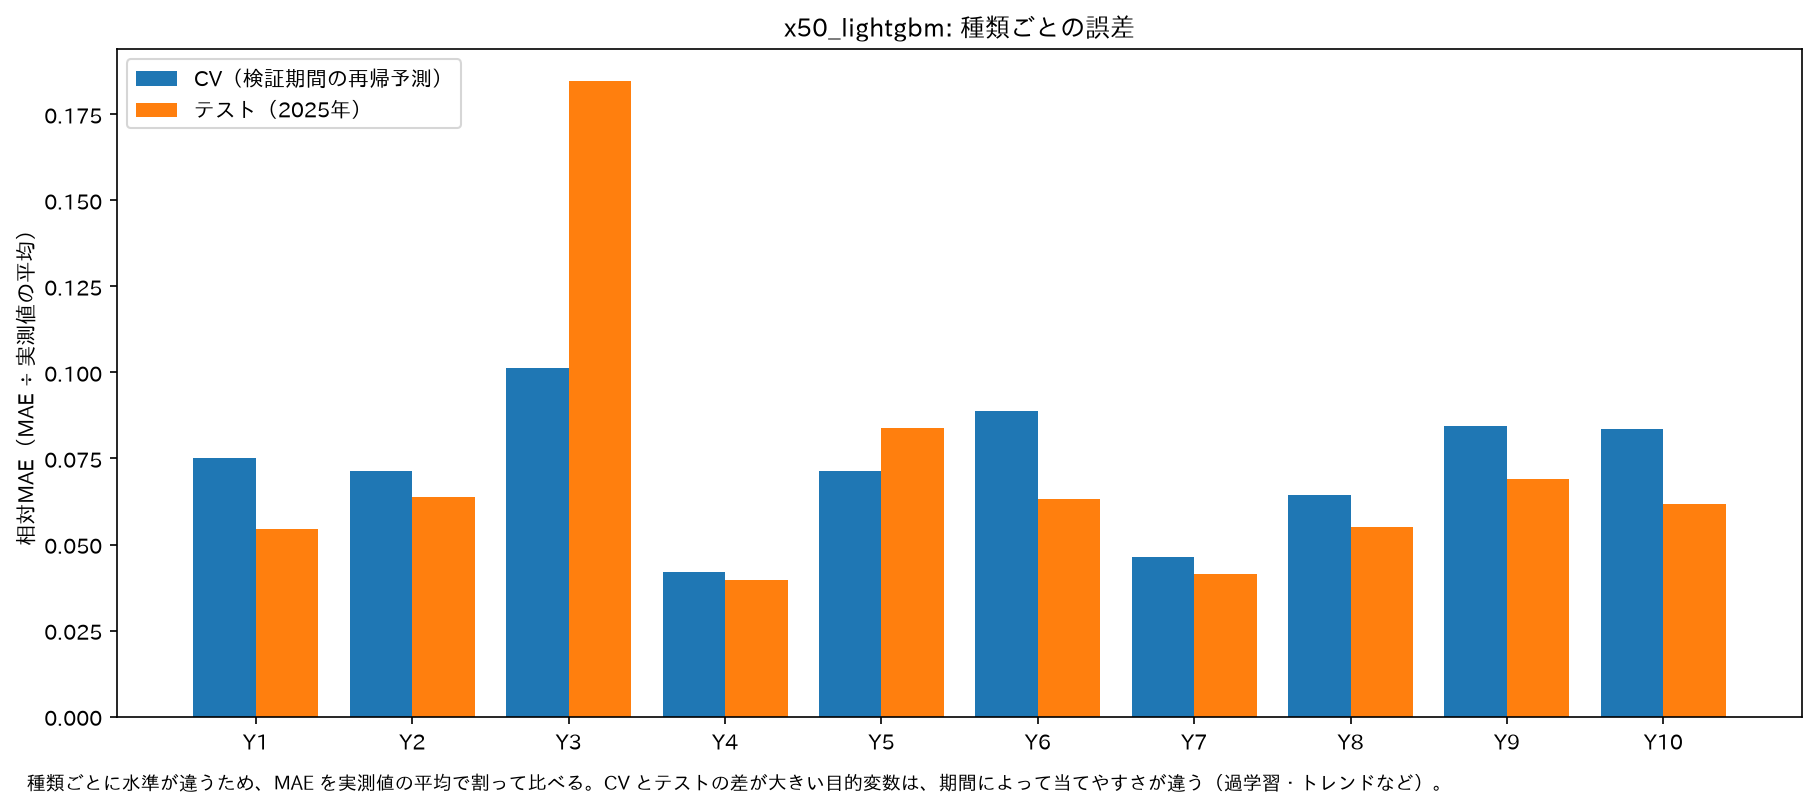

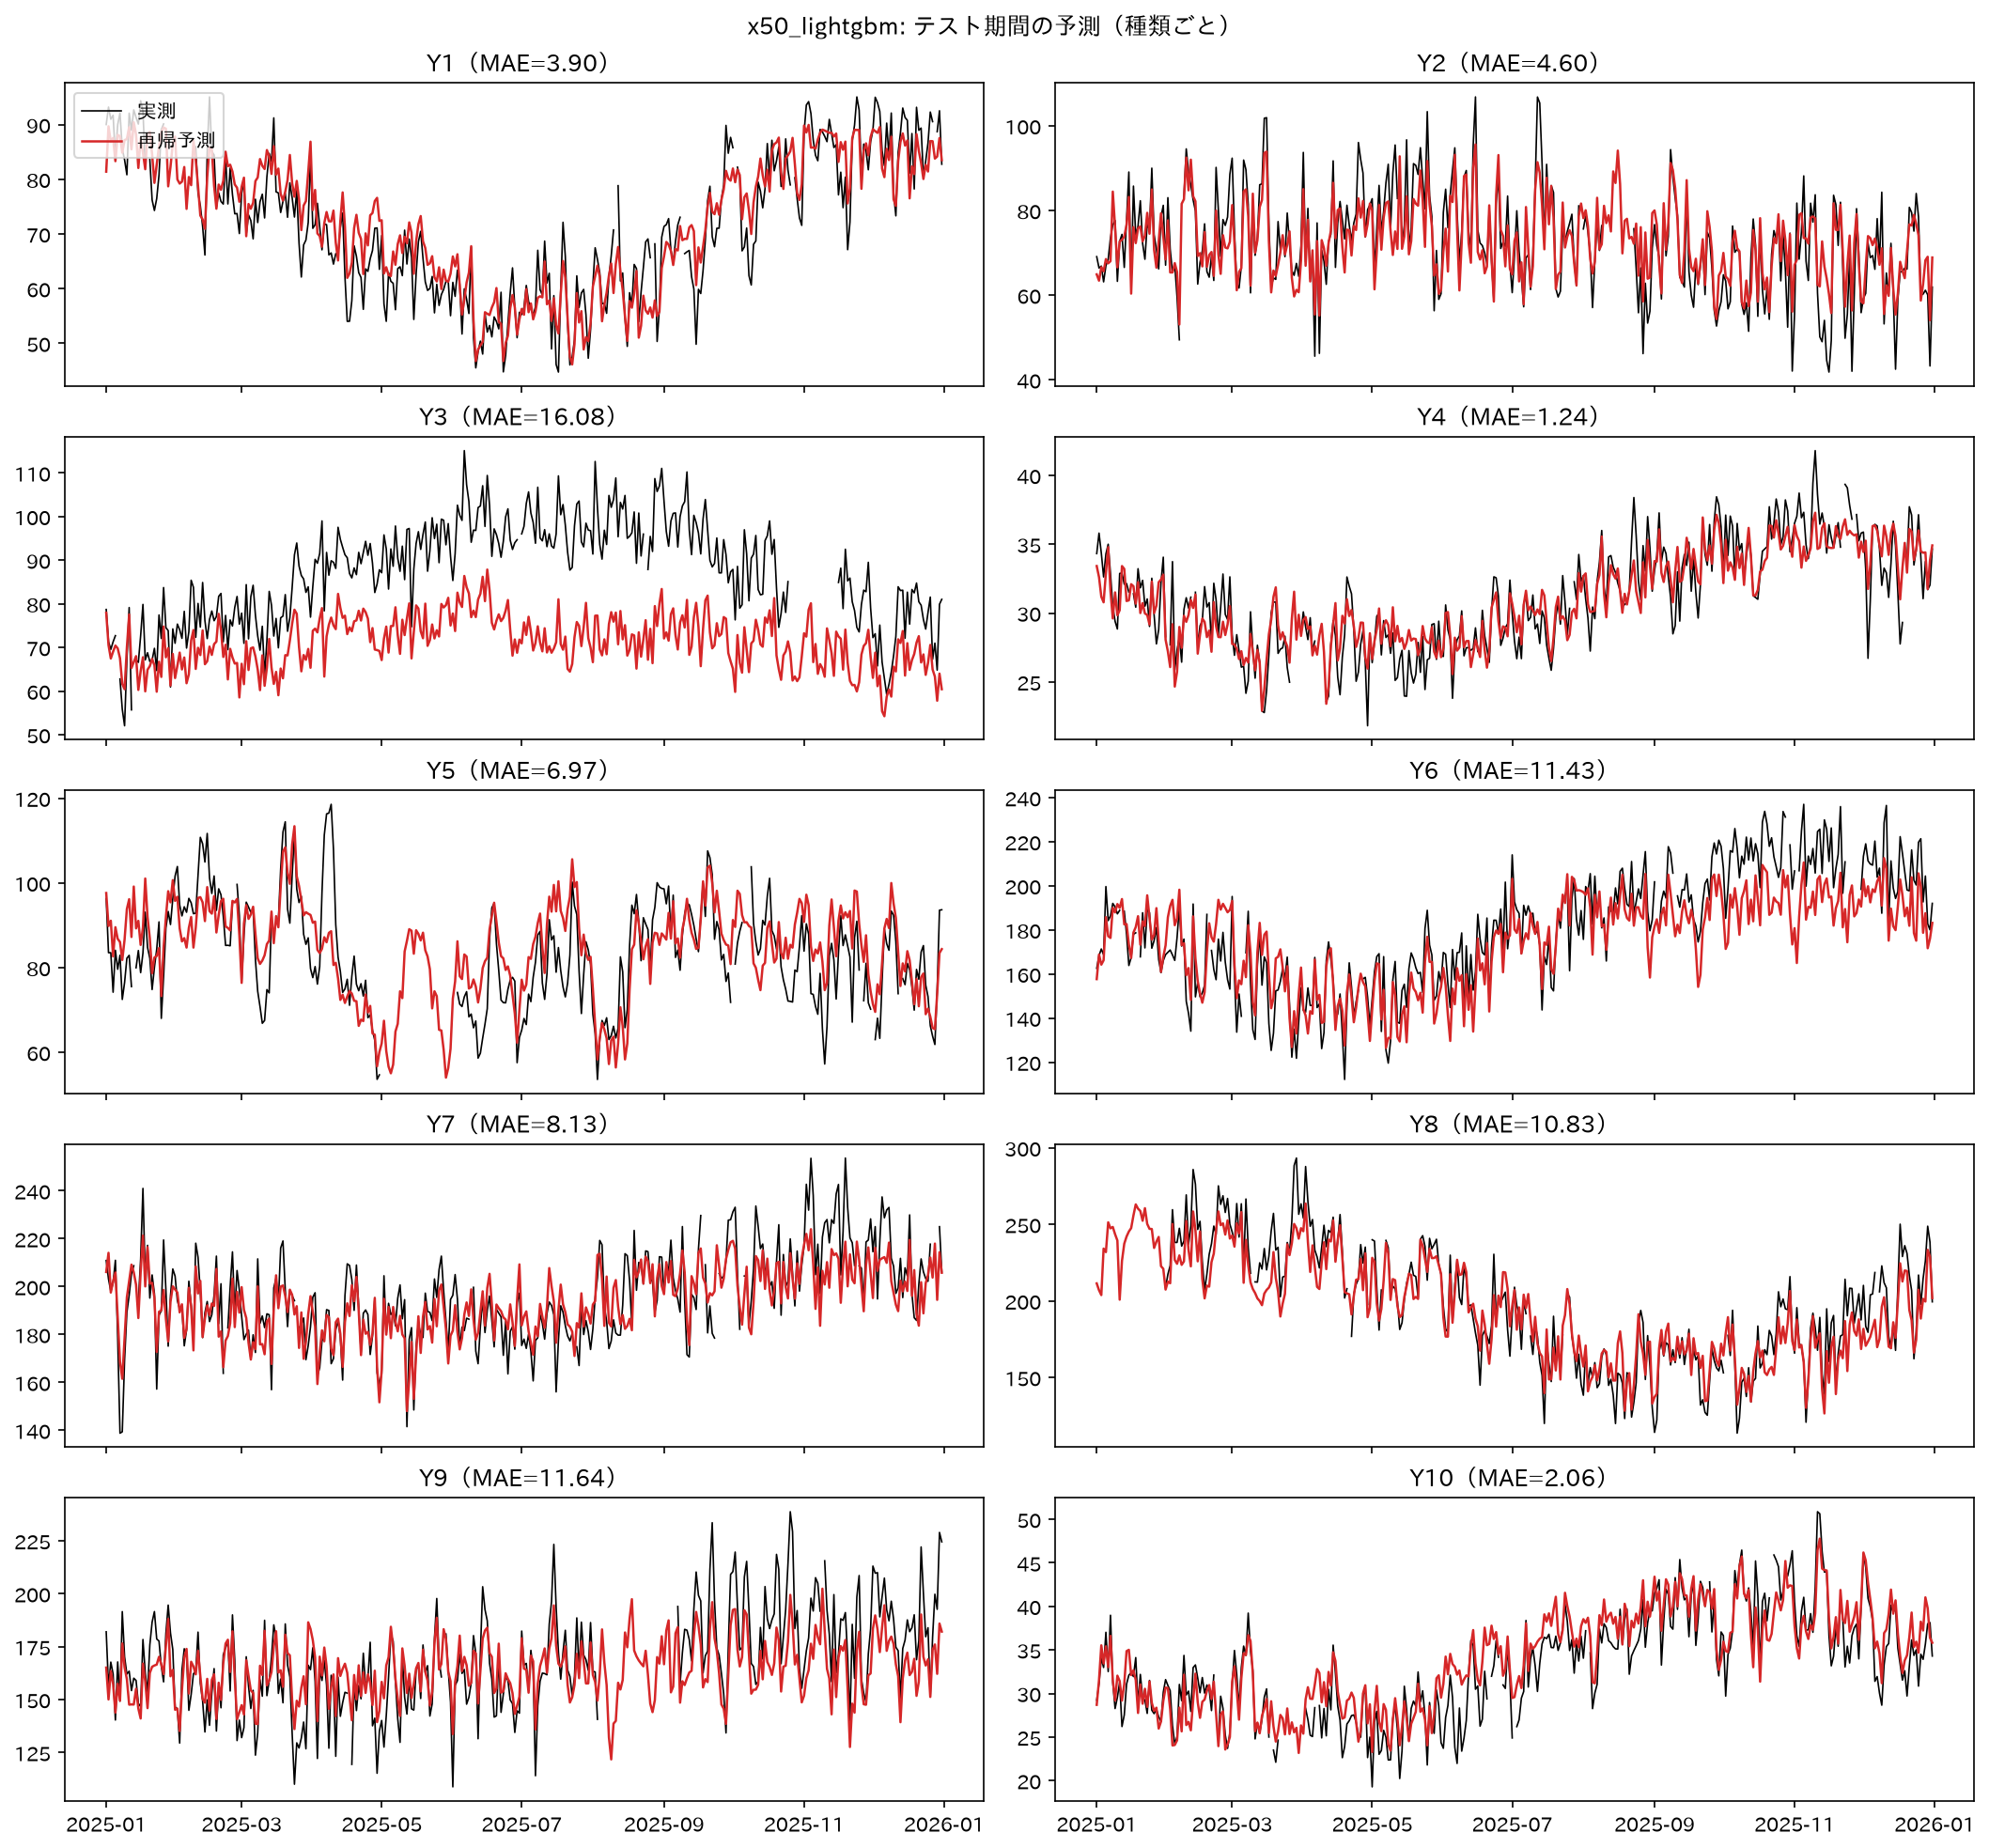

In [21]:
figures = summary_dir / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "test_overview.png"), width=1000))

## 8. SHAP によるモデル解釈（全種類）

種類ごとの SHAP 重要度（平均 |SHAP 値|）を、種類ごとに合計1の割合にして並べる。
各種類自身のラグ・移動平均・前日比は「自身_lag_1」などとして表示する。どの説明変数がどの種類に効いているかを比べられる。

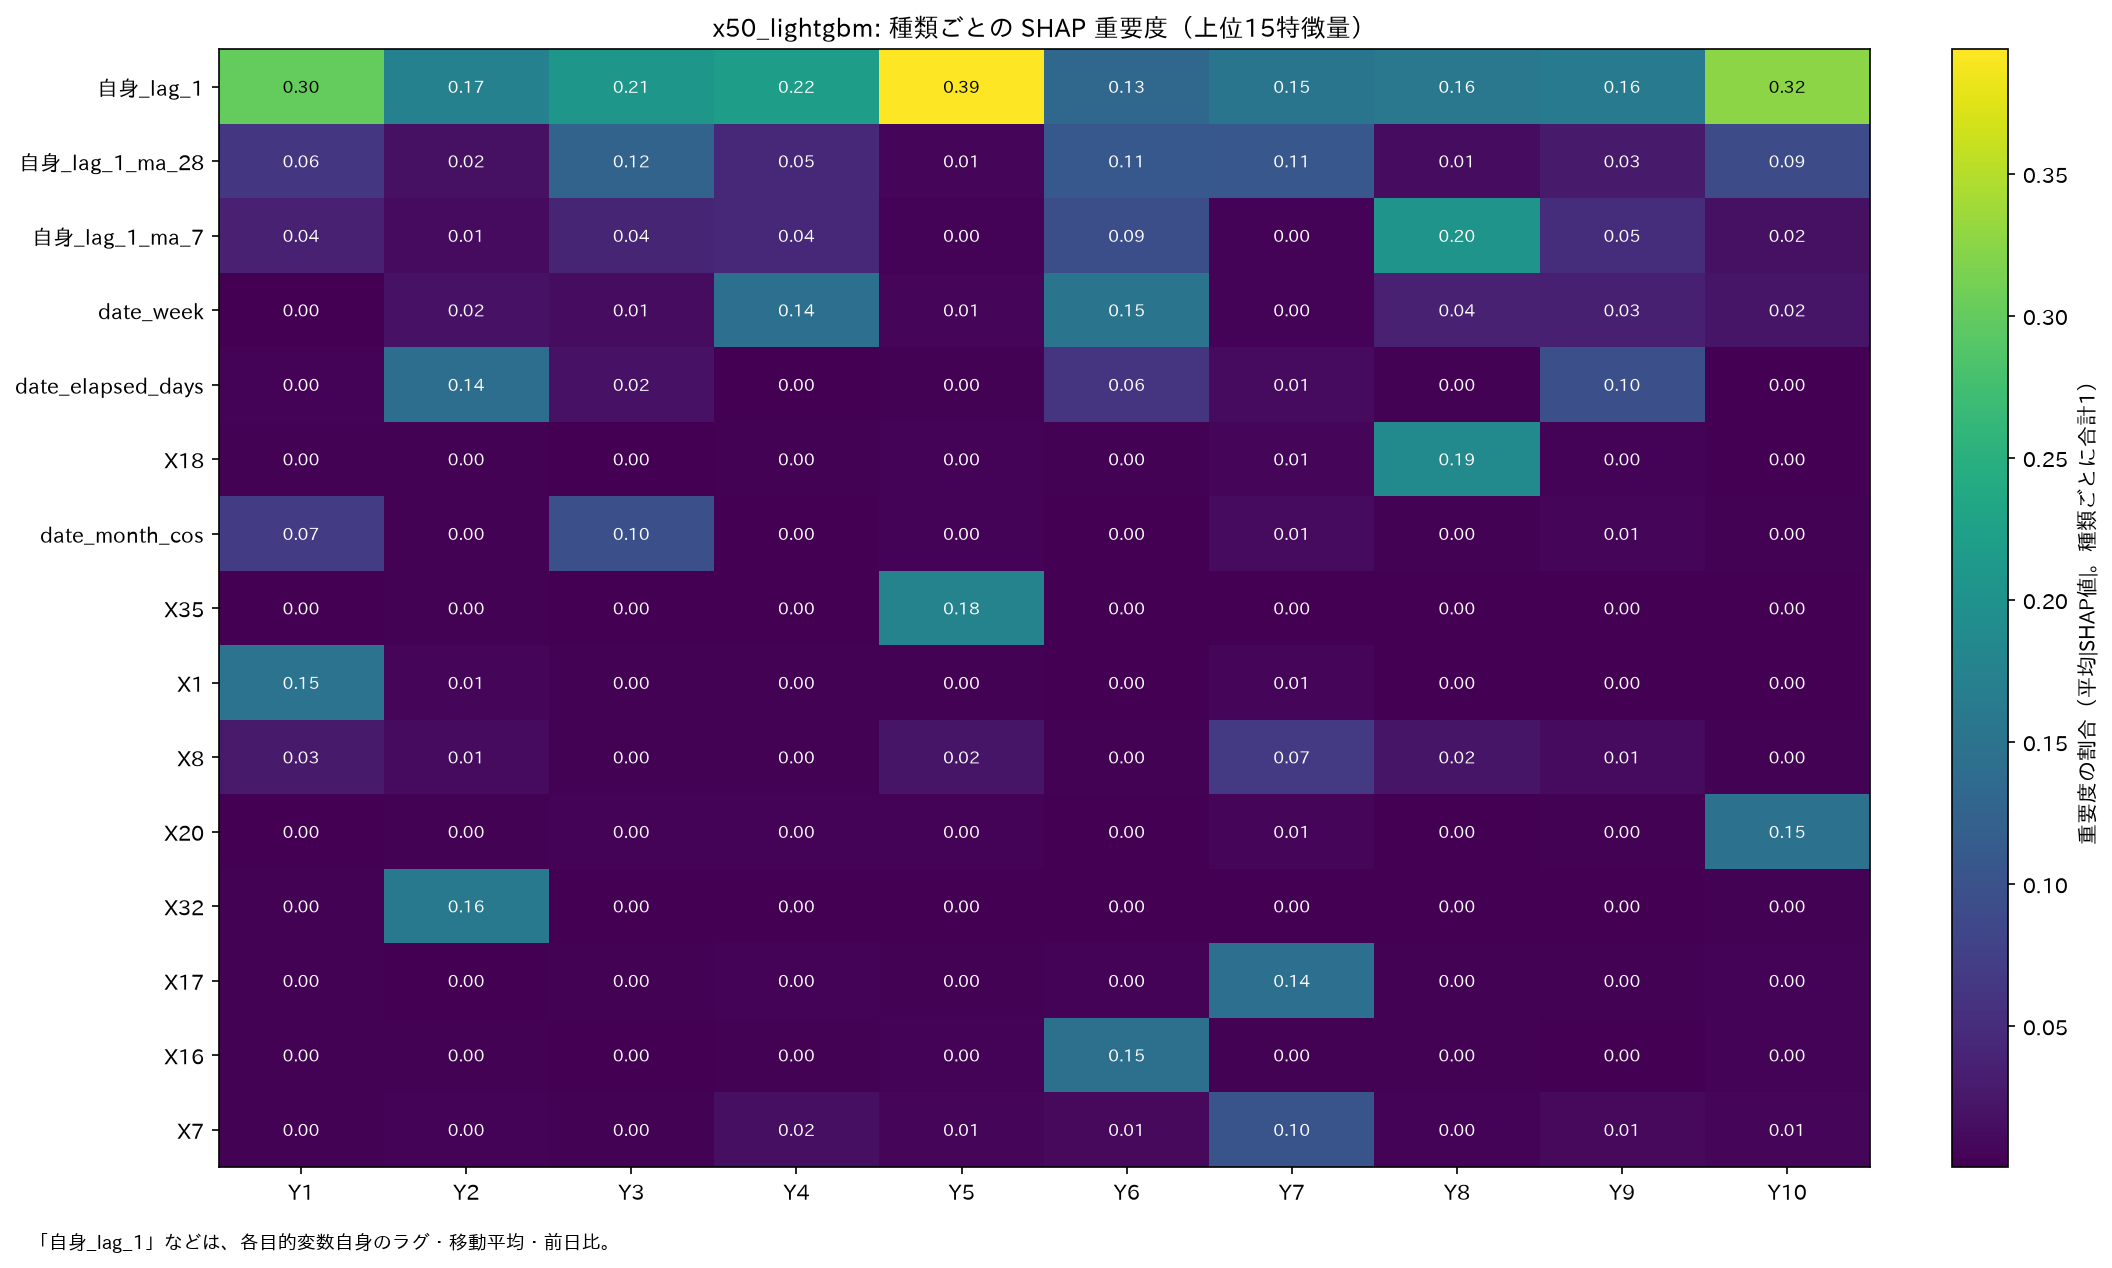

In [22]:
display(Image(filename=str(figures / "shap_overview.png"), width=800))

## 9. 1つの種類の詳細（`DETAIL_TARGET`）

### 学習結果

- **学習期間の実測値と検証期間の再帰予測:** 各 fold の検証期間（網掛け）を、実測値を使わずに予測した結果。
- **予測ステップ別の MAE:** 検証期間の何日目の予測かごとの MAE。先の日ほど誤差が積み重なる。
- **学習の推移:** 木の本数ごとの学習・検証の損失（対数の尺度）。

Y1: outputs/experiments/x50_lightgbm_Y1/20261029_054218_045390


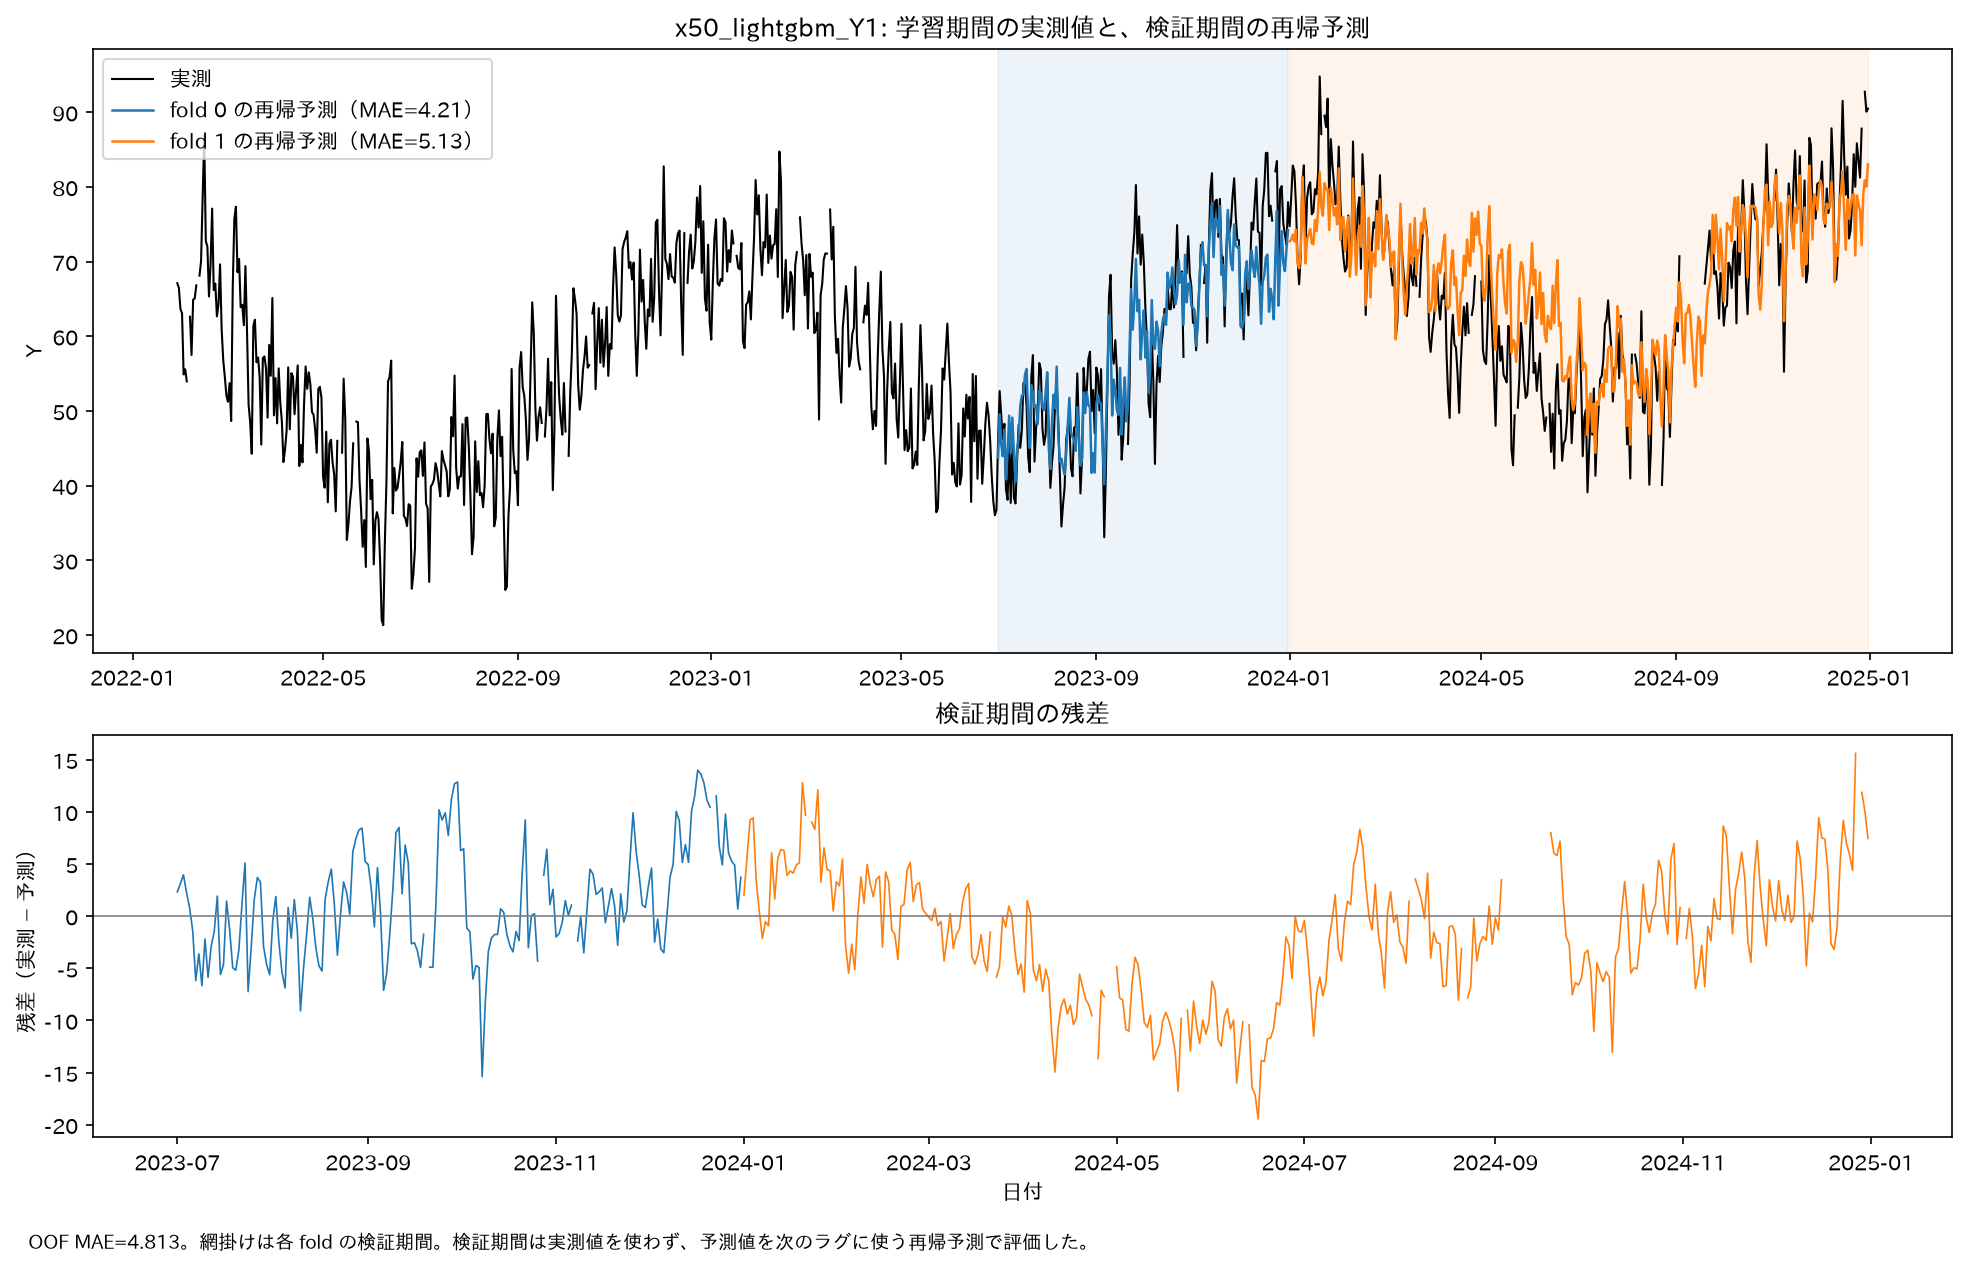

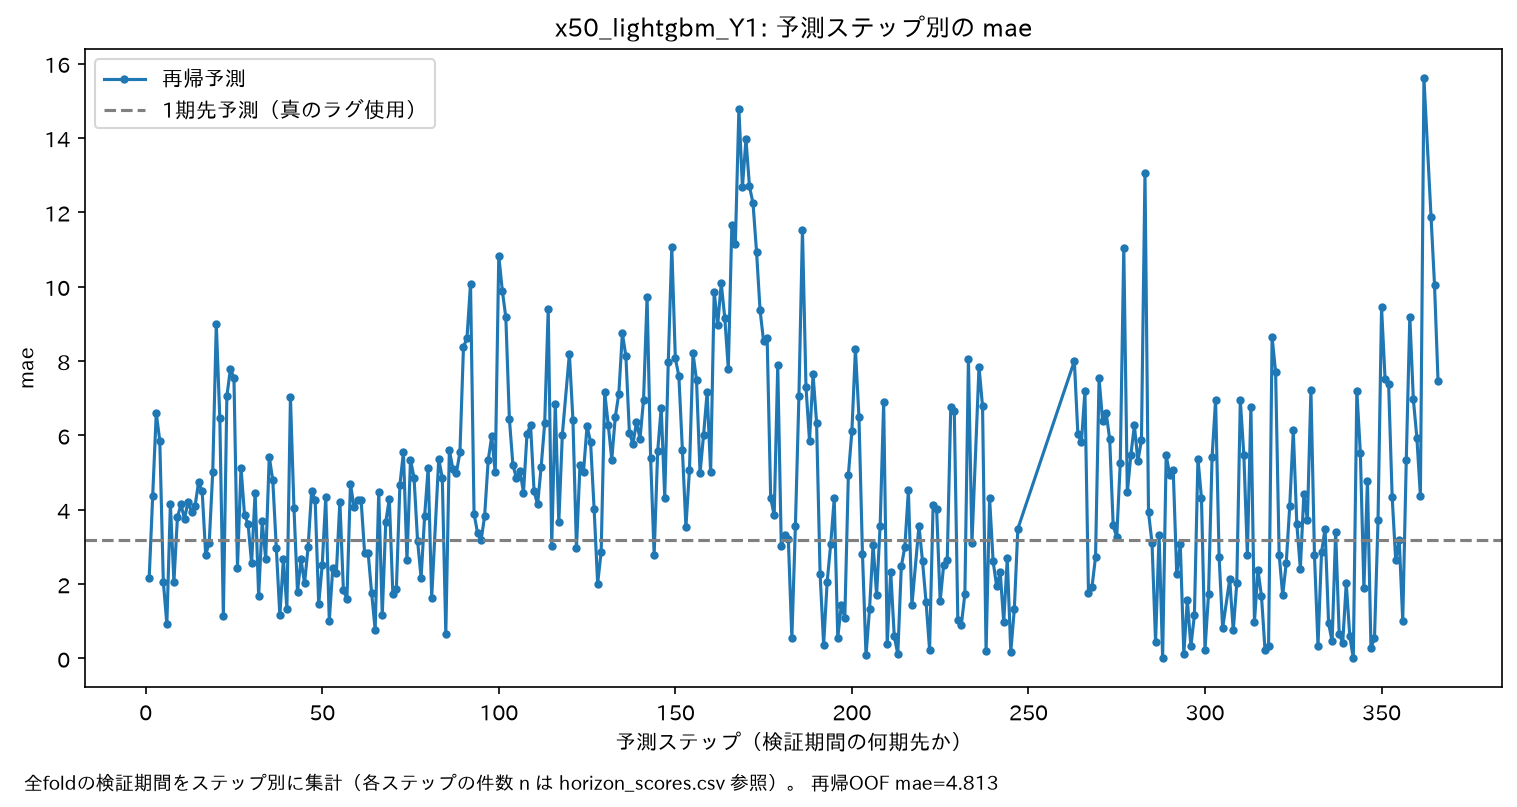

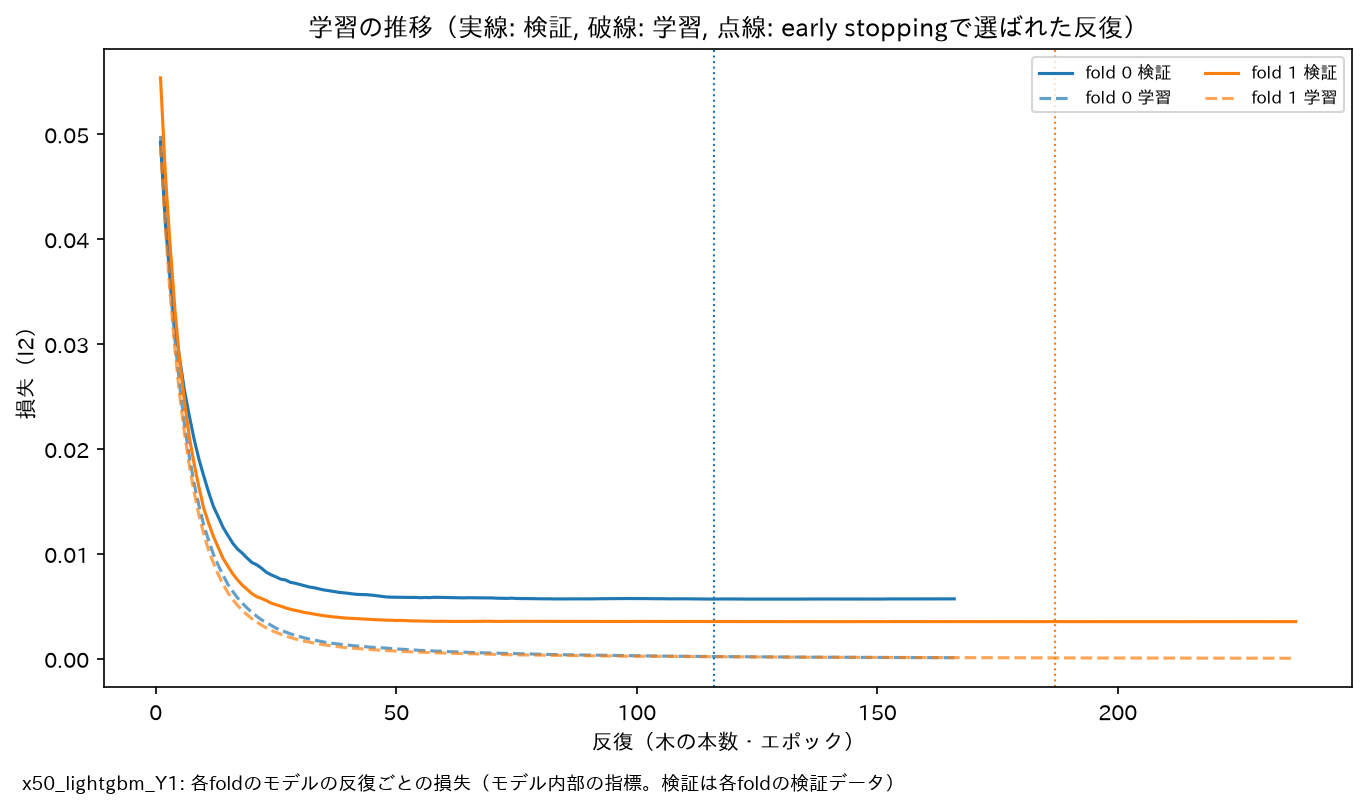

In [23]:
detail = next(run for run in runs if run.category == DETAIL_TARGET)
out = detail.result.output_dir
print(f"{DETAIL_TARGET}: {shown(out)}")
display(Image(filename=str(out / "figures" / "training_result.png"), width=1000))
display(Image(filename=str(out / "horizon_error.png"), width=800))
display(Image(filename=str(out / "evaluation" / "training_history.png"), width=800))

検証期間の残差の診断（`modeling.evaluation` が作る図）。残差に偏り・自己相関が残っていないかを見る。

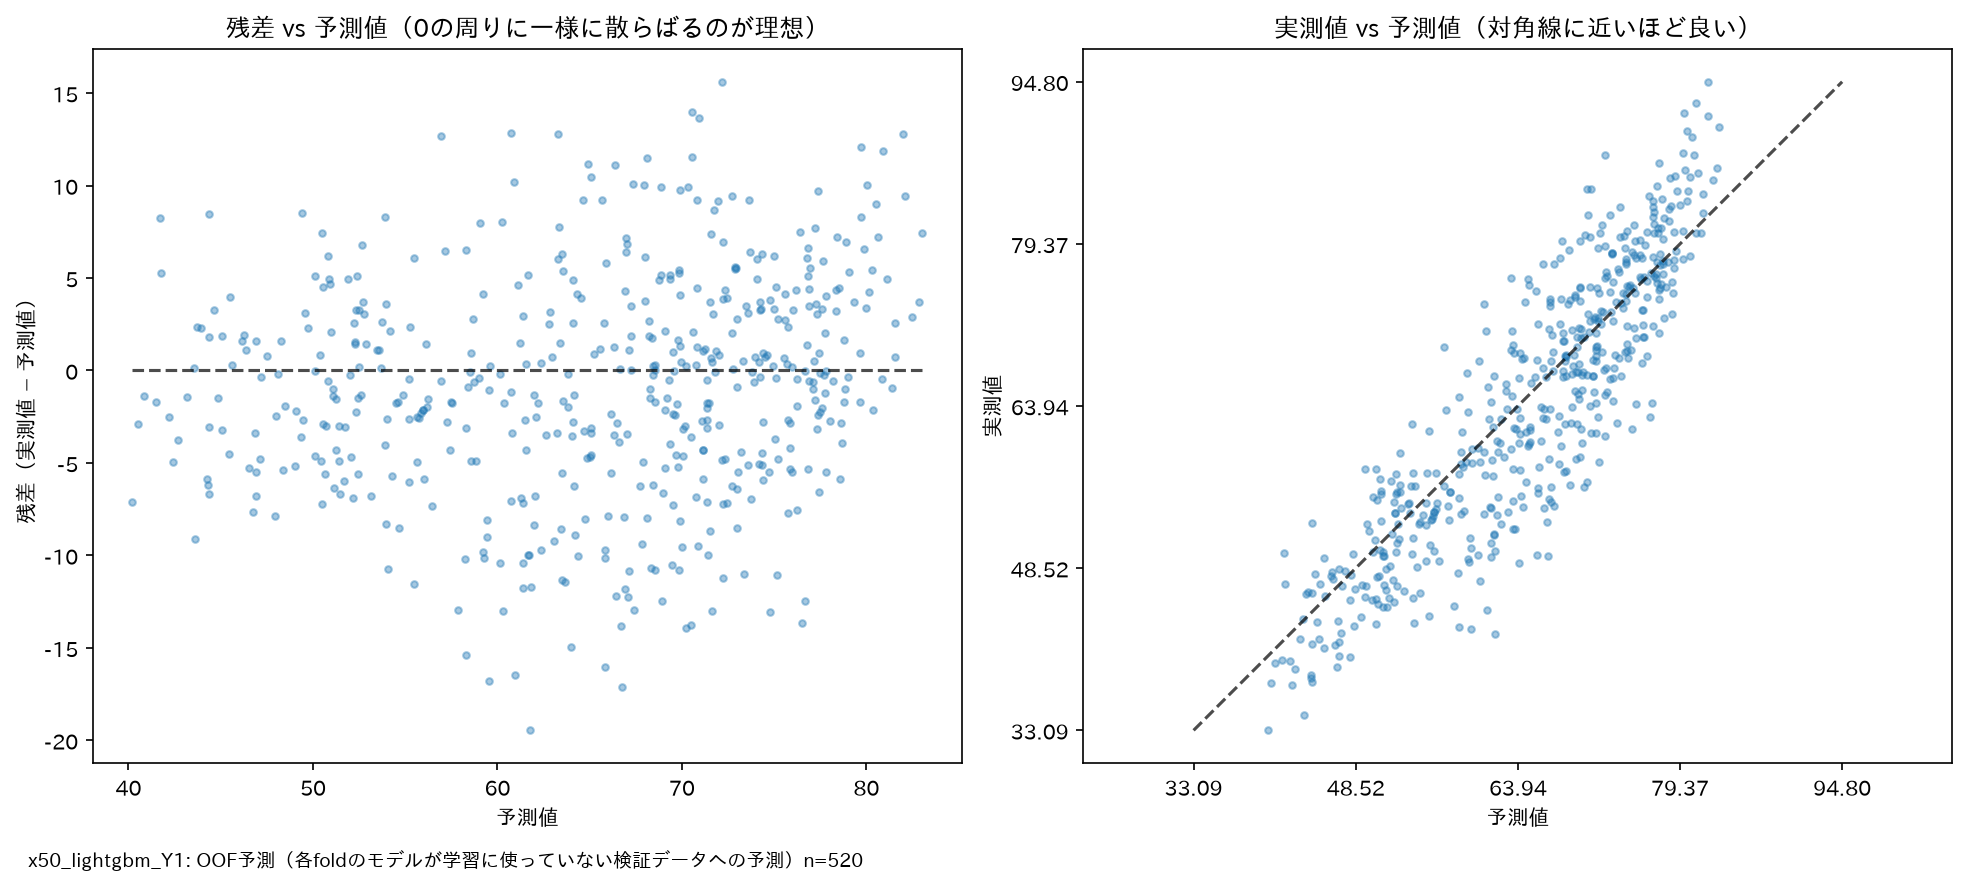

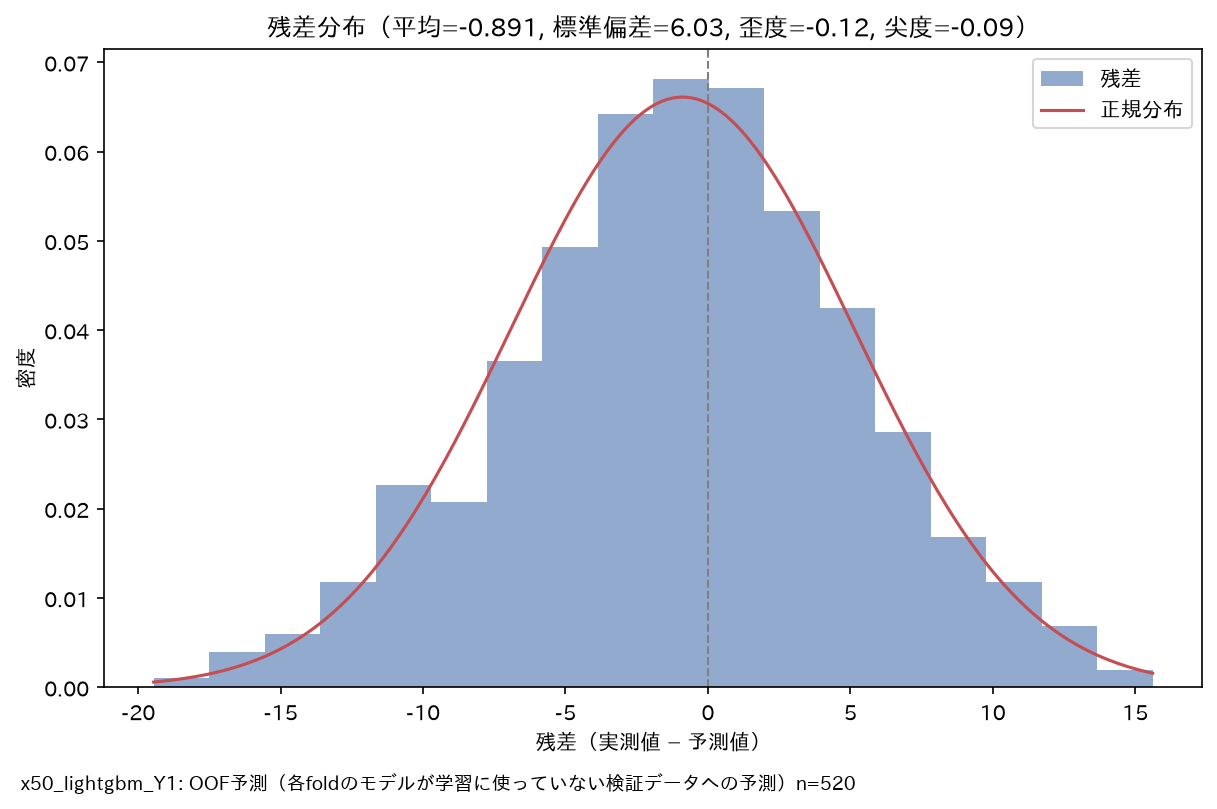

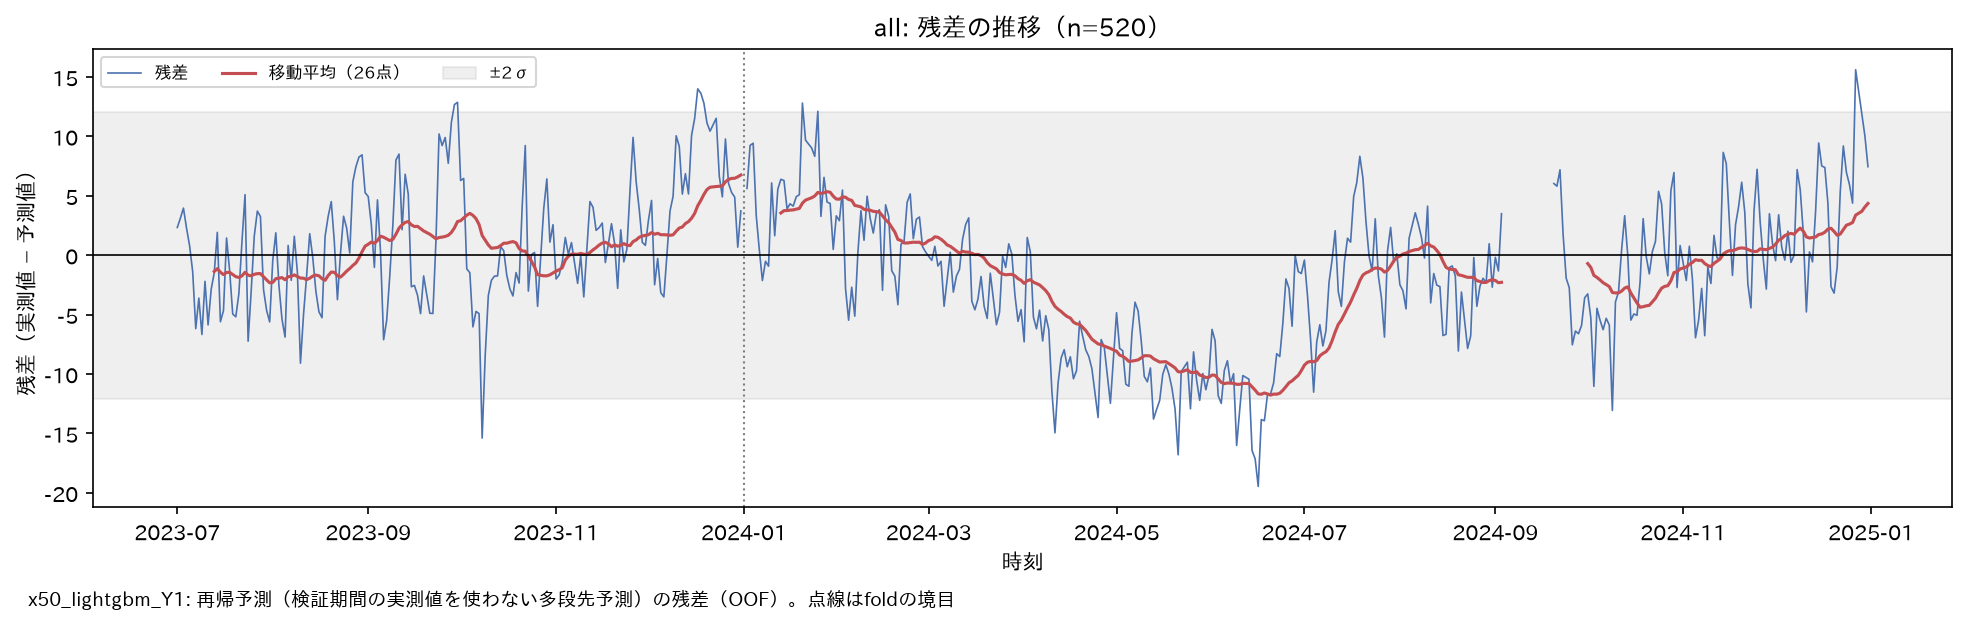

In [24]:
for name in ("residual_plot.png", "residual_distribution.png", "residual_timeseries.png"):
    display(Image(filename=str(out / "evaluation" / name), width=850))

### テスト結果

テスト期間（2025年）の再帰予測と実測値、予測と実測の散布図、月別の MAE。

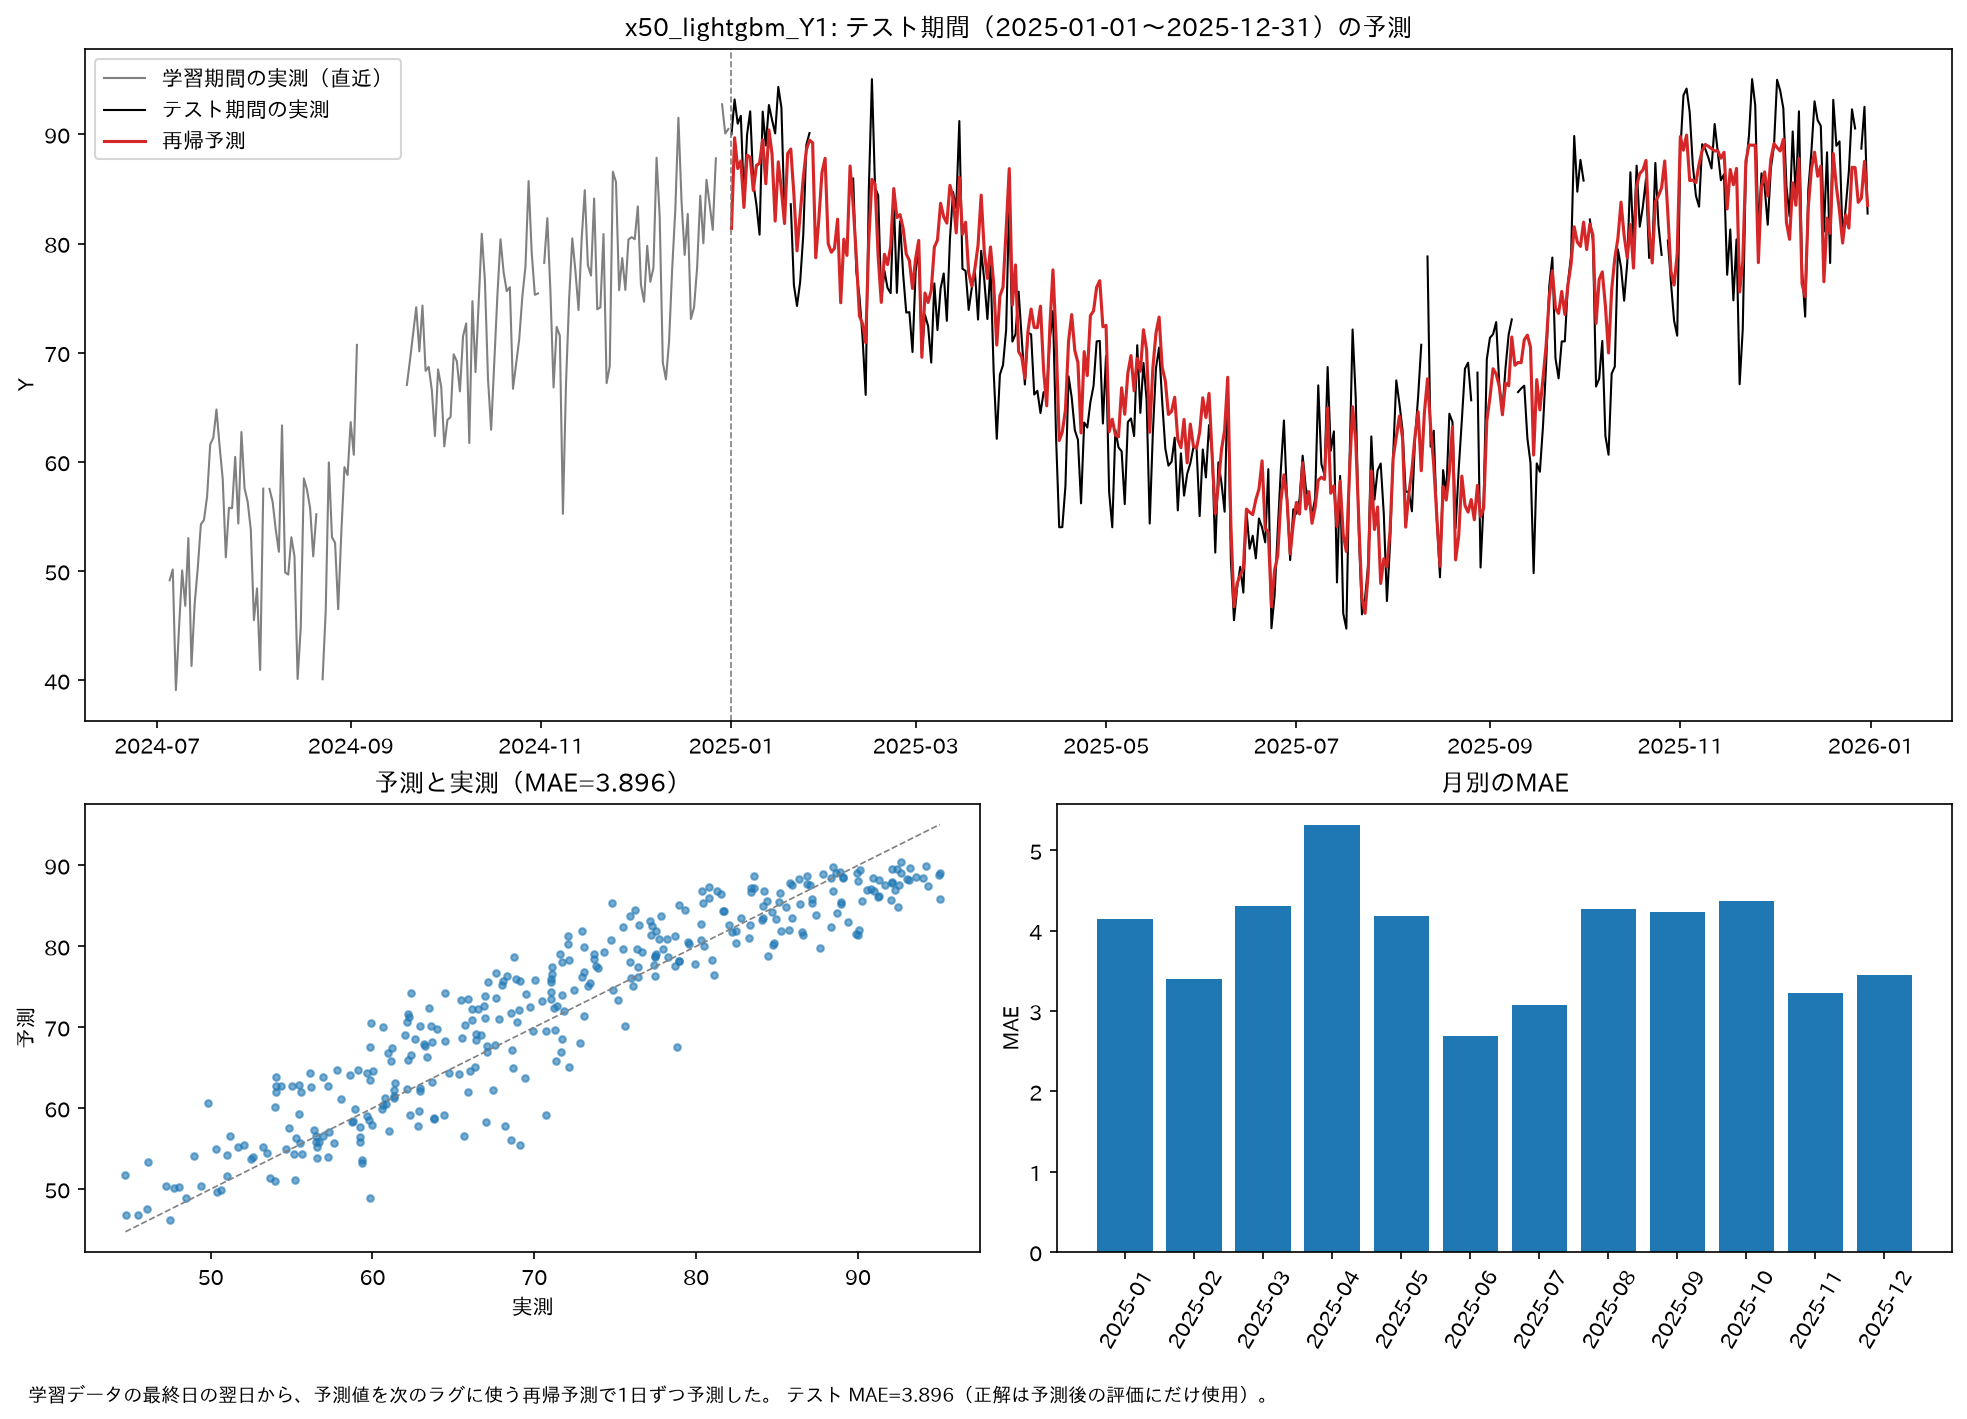

In [25]:
display(Image(filename=str(out / "figures" / "test_result.png"), width=1000))

### SHAP によるモデル解釈

各 fold のモデルを、その検証期間のデータで説明した SHAP 値（OOF SHAP）。モデルは目的変数の対数を予測するため、
SHAP 値も対数の尺度（例: 0.01 は予測値を約1%押し上げる）。

- **重要度:** 平均 |SHAP 値| の大きい特徴量ほど予測への影響が大きい。
- **beeswarm:** 各点が1日。色は特徴量の値（赤=大きい）、横軸は予測への寄与。
- **効きの向き:** 特徴量の値が大きいほど予測を押し上げる（赤）か、押し下げる（青）か。
- **依存関係:** 上位の特徴量の値と SHAP 値の関係。

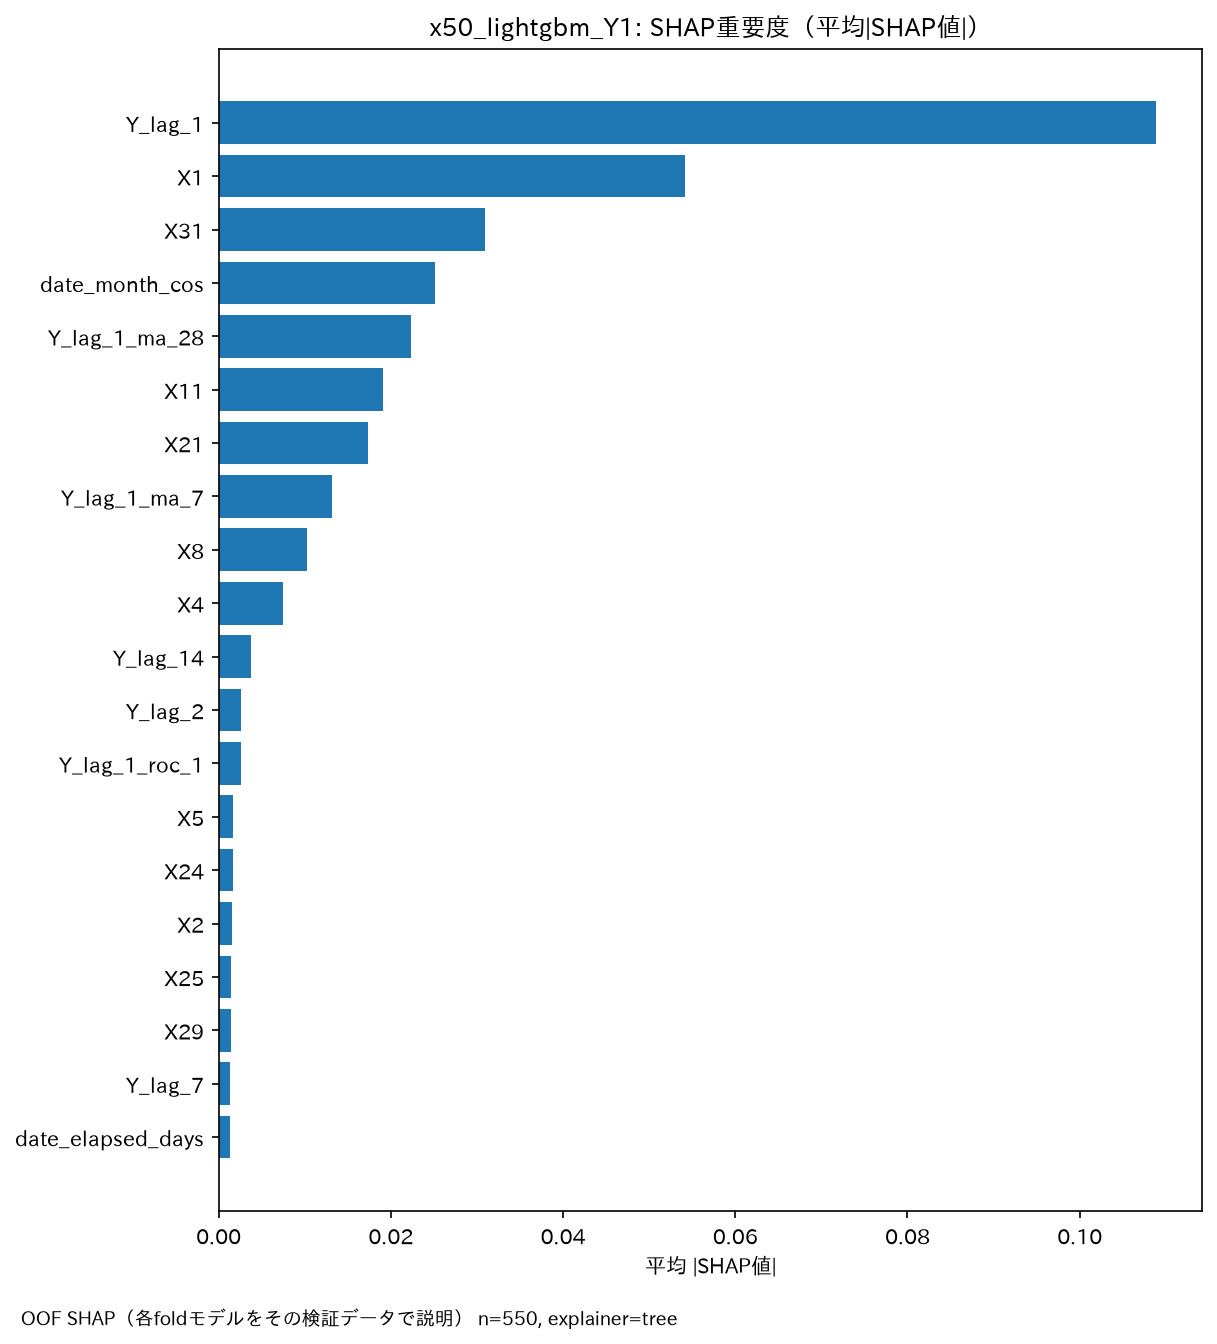

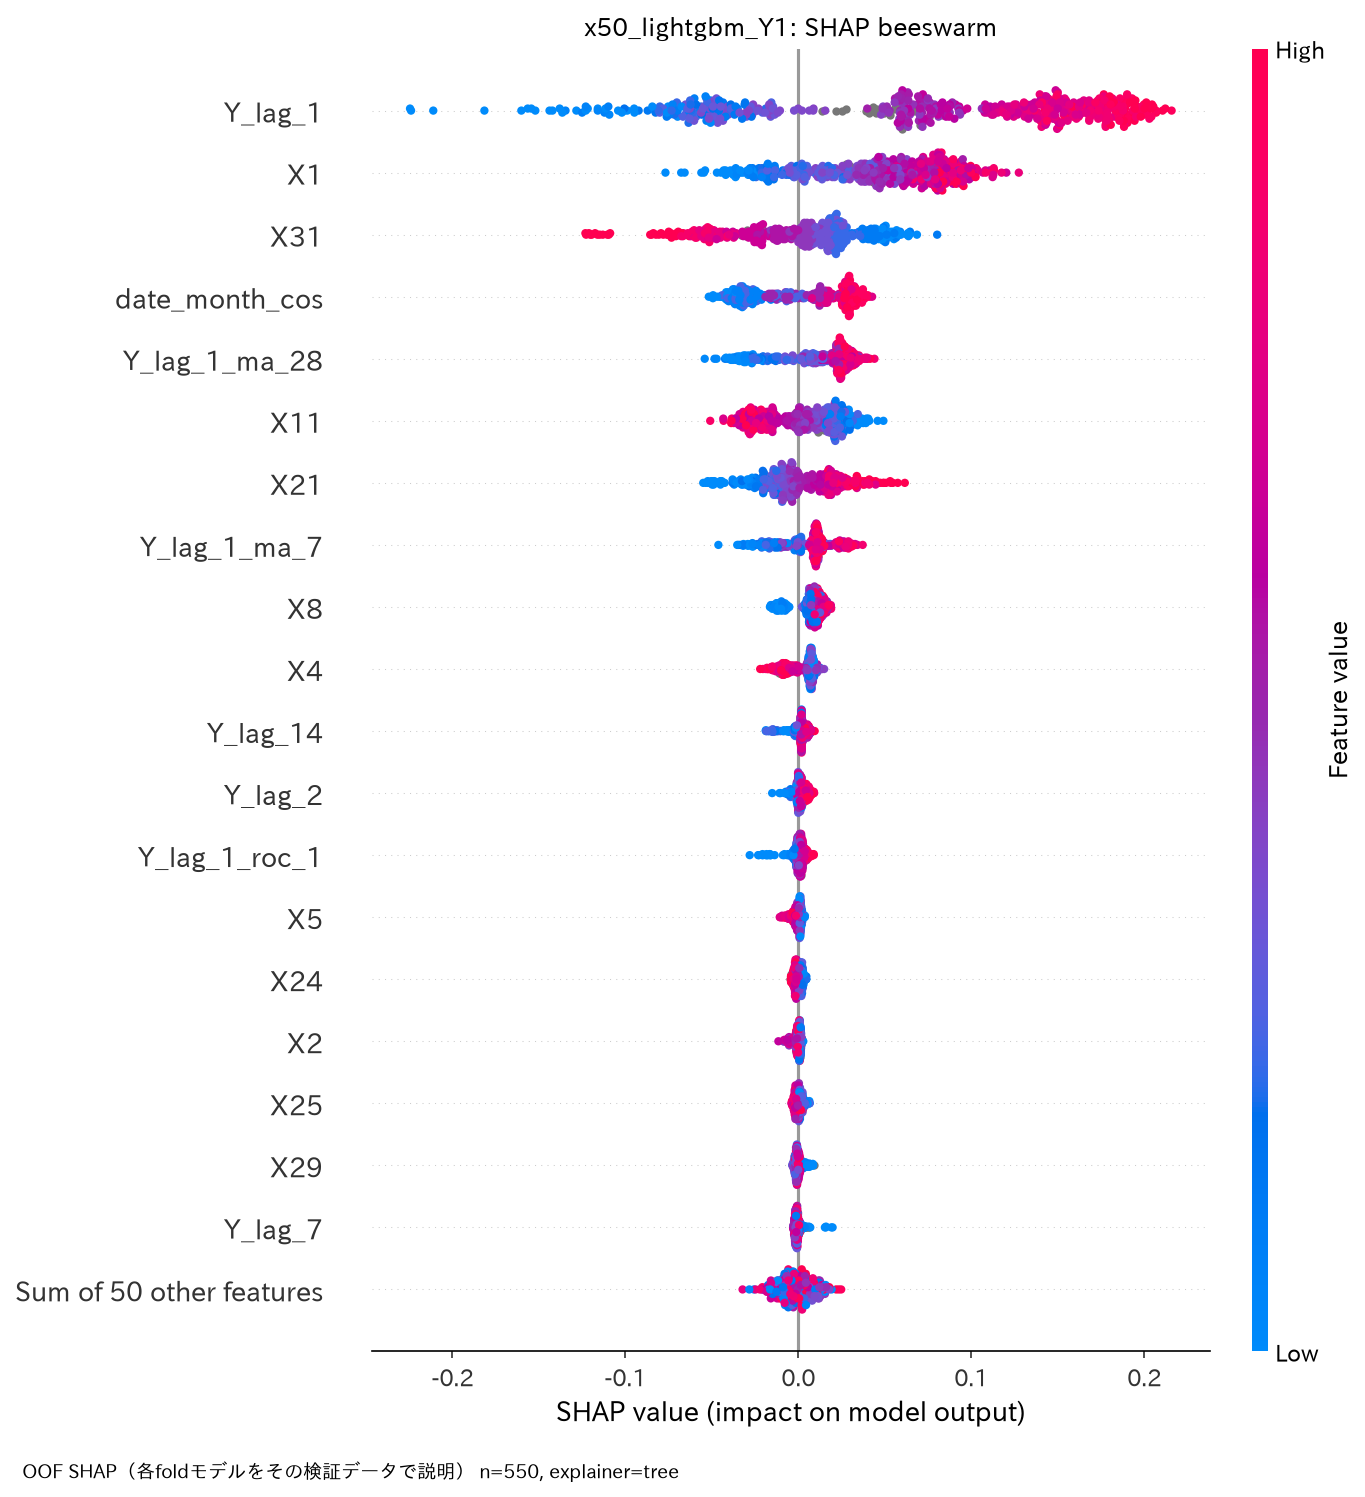

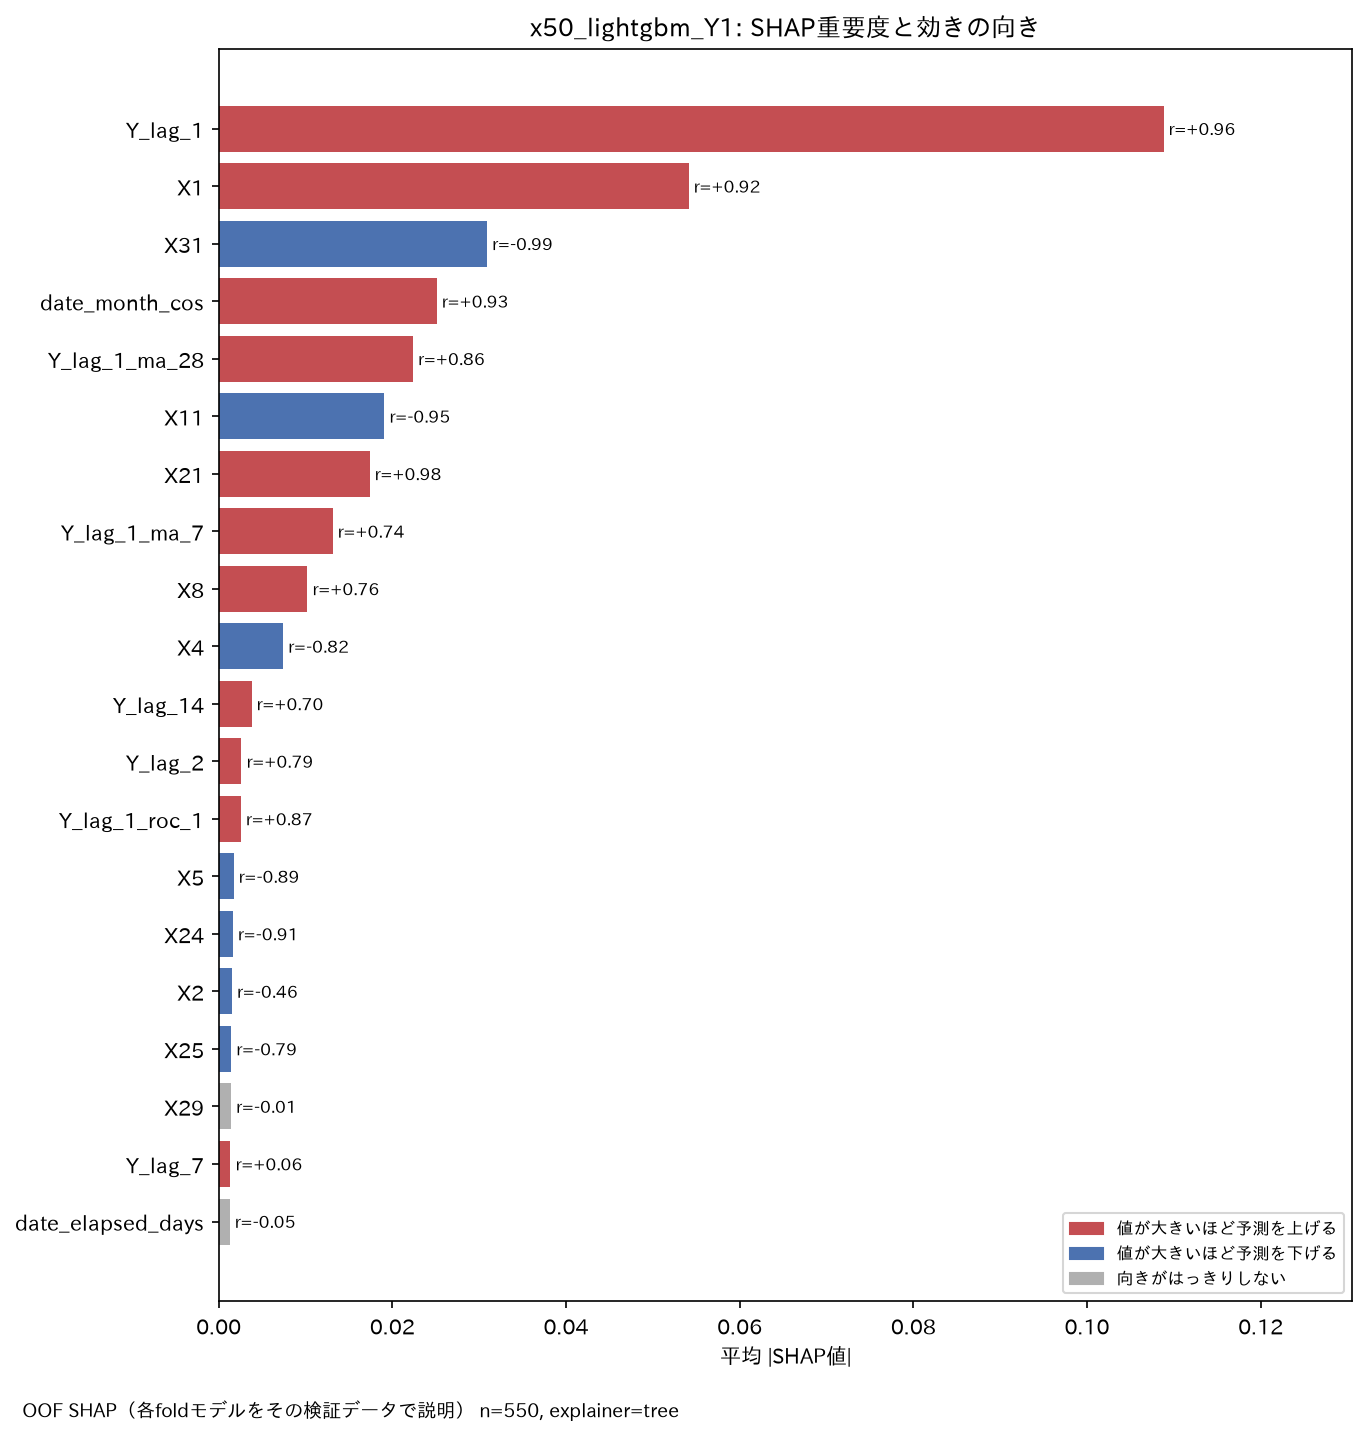

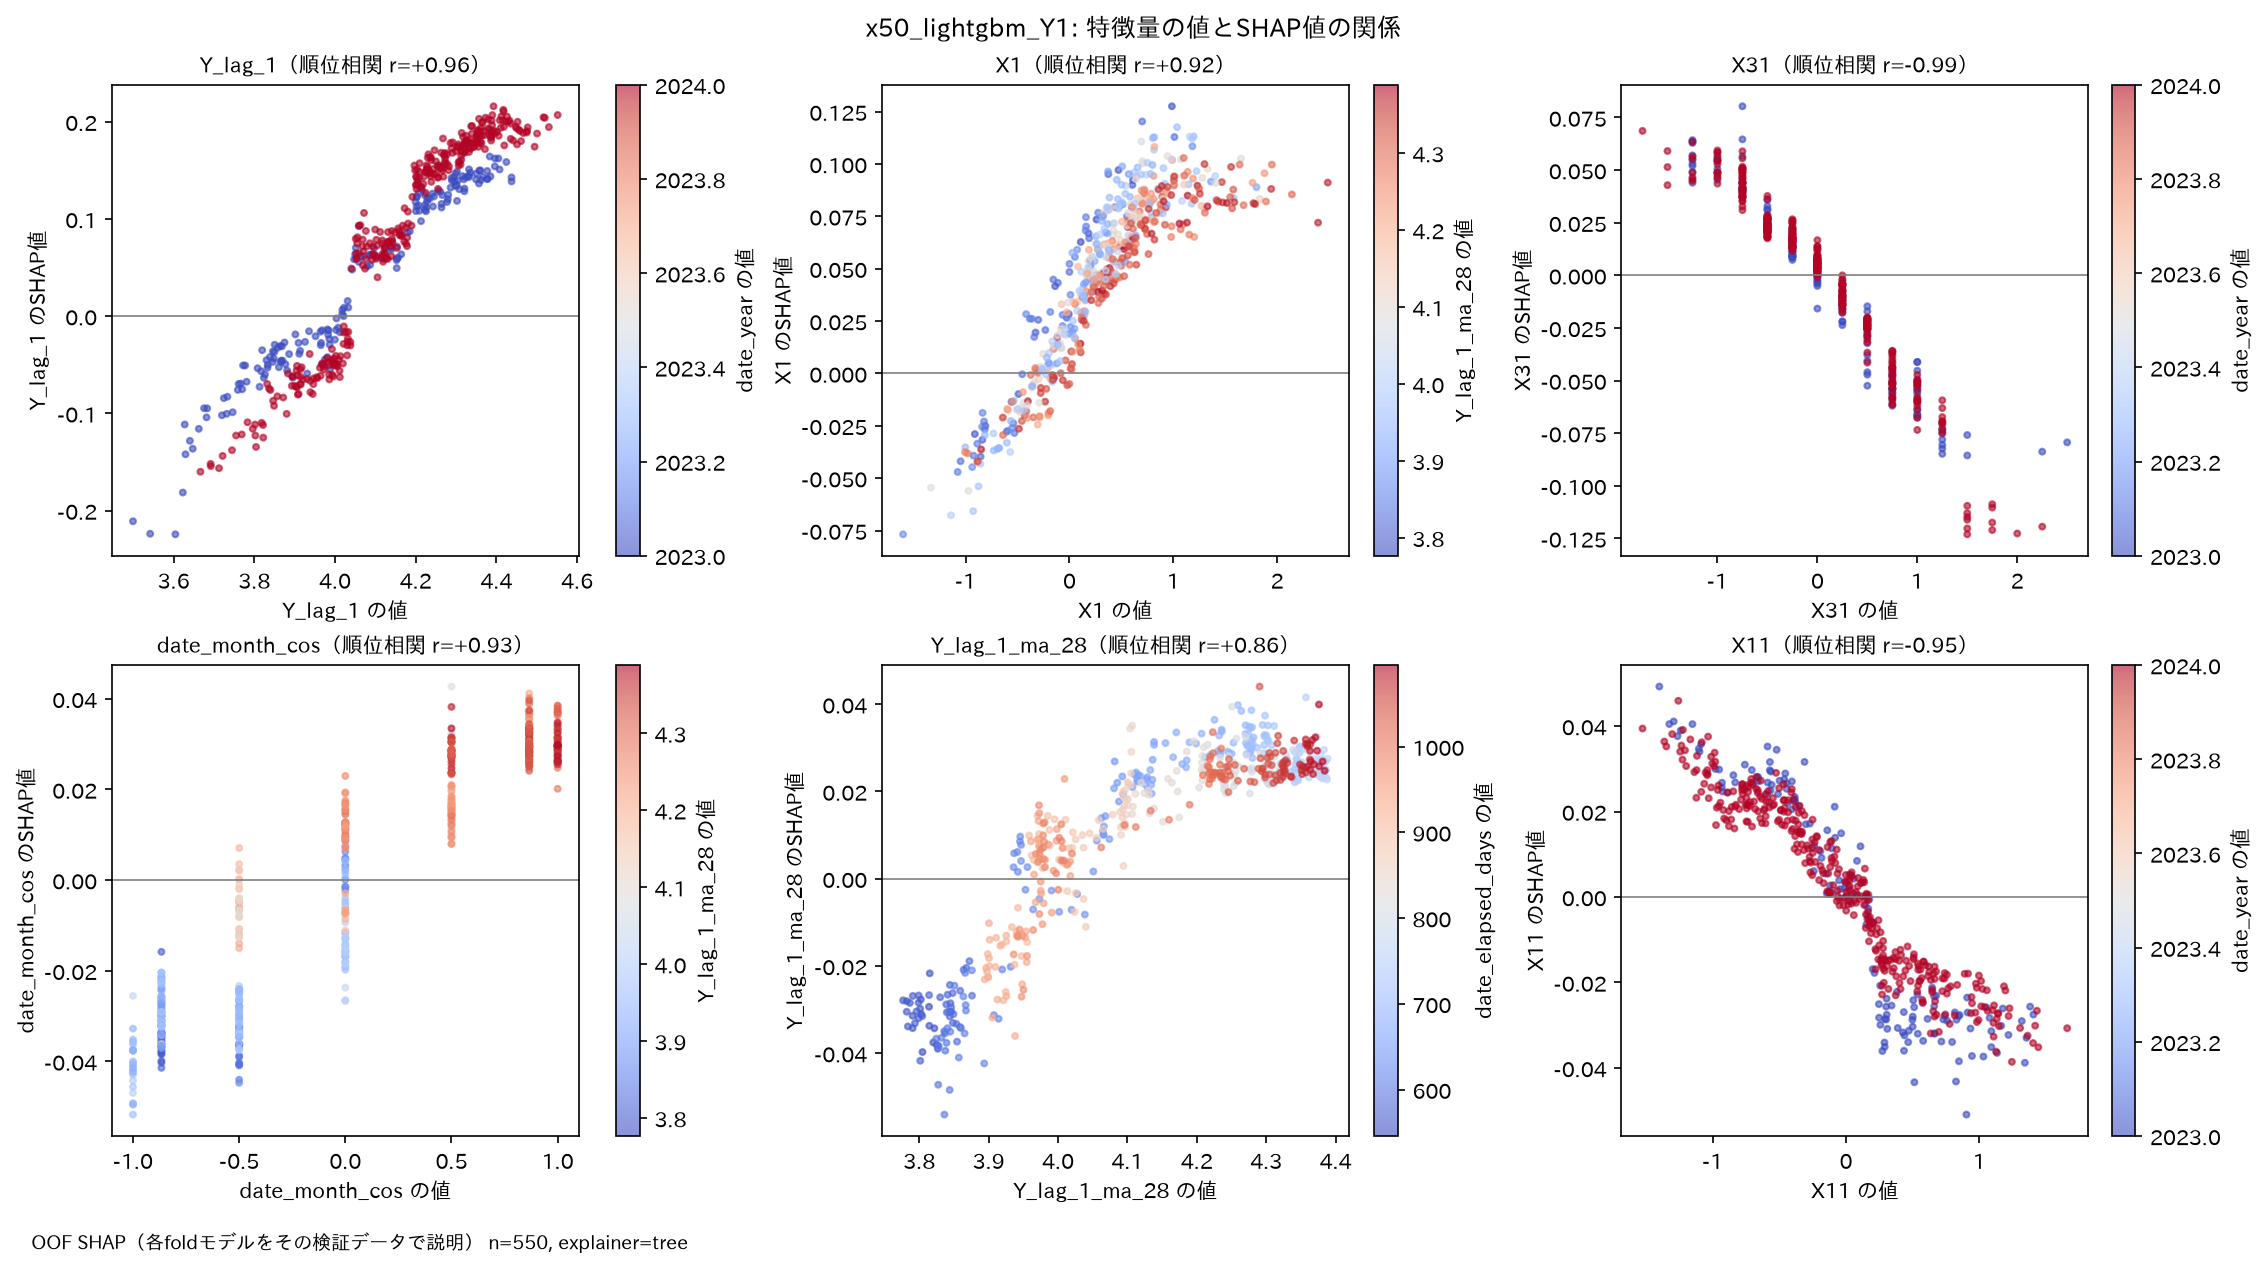

In [26]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(shap_dir / "shap_correlation_bar.png"), width=800))
display(Image(filename=str(shap_dir / "shap_dependence.png"), width=1000))

## まとめ

- 前半で、long 型の生データの目的変数・日付・説明変数のそれぞれに `src/feature_engineering` の前処理をかけ（学習が必要な
  ものは学習データだけで fit）、前処理済みの CSV（long 型）を出力した。
- 後半で、種類（`Y_cat` = Y1〜Y10）ごとに、その種類の行だけで選んだモデルを学習し、2025年を再帰予測した。目的変数のラグ・
  移動平均は、検証・テスト期間では予測値から作り直している。各モデルは自分自身のラグだけを使い、他の種類の値は使わない。
- 前処理と再帰予測のそれぞれで、入力を書き換えるリークの確認を行った。CV は本番と同じ条件（検証期間の実測値を使わない
  再帰予測）で評価しているため、CV の MAE とテストの MAE を比べて、過学習や期間による違いを確認できる。
- ログはファイル（`outputs/logs/`、要約ディレクトリの `run.log`）と MLflow（種類ごとの run と要約の run。
  同じ `batch` タグで結び付く）に残している。

**注意点**

- 種類ごとに水準が違うため、種類をまたいで比べるときは相対MAE を使う。
- トレンドのある種類（ダミーでは Y3・Y6・Y9）は、テスト期間に学習範囲より高い水準になる。木のモデルは学習範囲の
  外へ外挿できないため、テストの誤差が CV より大きくなりやすい（差分の変換などを検討する）。
- 日付の特徴量 `date_year` は、テスト期間（2025年）の値が学習データに無い。
- 説明変数の欠損（X21〜X30）は埋めていない（LightGBM・XGBoost は欠損をそのまま扱える）。
- 目的変数が欠損の日は、CV・テストの評価から除いている。長い連続した欠損の直後は、ラグ・移動平均が欠損または
  少ない観測値から作られるため、予測が不安定になりやすい。
- SHAP は検証期間（OOF）での説明。テスト期間のモデル（学習データ全体で学習し直したもの）とは、学習に使った期間が違う。